# U6 GHz Interference and Coexistence Simulator

Supplementary material for "Interference and Coexistence in the Upper 6 GHz Band: A Practical Framework for 5G-Advanced and 6G Giga-MIMO Deployment", IEEE Open Journal of the Communications Society.

The notebook evaluates interference in the Upper 6 GHz band (6425–7125 MHz, 3GPP band n104, TDD) between a Giga-MIMO mobile network and three victim systems: Fixed Service links, geostationary FSS satellites and Wi-Fi. The 3.5 GHz comparison layer is 5G NR band n78. All models are embedded; the notebook needs only `numpy` and `matplotlib`, and *Run all* takes about two minutes in Google Colab.

Two engines share one set of propagation and antenna models. Engine A is a Monte Carlo aggregation over 400 deployment snapshots and evaluates the Fixed Service and FSS victims. Engine B is a deterministic link model and evaluates the IMT–Wi-Fi case and the coverage comparison. The mitigations evaluated are guard band, geographic separation, AFC, beamforming avoidance, power reduction, indoor/outdoor partition and sensing (LBT).

The models are 3GPP TR 38.901 UMa NLOS, ITU-R P.2109 building entry, P.1238 indoor loss, P.2108 clutter, the P.452-16 smooth-earth loss for the Fixed-Service path, the ITU-R M.2101 composite array pattern and the F.1245 Fixed-Service dish. The M.2101 implementation agrees with pycraf 2.1.0 to within 1e-7 dB. The P.452 losses are an embedded table computed with pycraf, which `generate_p452_table()` can rebuild when pycraf is installed. The Wi-Fi airtime mapping is calibrated to the measured BT/Nokia trial states; this agreement is an in-sample fit, not independent validation.

Regulatory values carry an inline `# [SRC: …]` tag. The deployment values in Section 5 (inter-site distance, EIRP, Fixed-Service and FSS geometry) are representative and should be replaced with operator planning data for any regulatory study.

## 1. Setup, constants and protection criteria
Requires only `numpy` and `matplotlib`.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, math
import matplotlib, matplotlib.pyplot as plt
from dataclasses import dataclass, field

print("numpy", np.__version__, "| matplotlib", matplotlib.__version__)

# ---- physical constants ----
SPEED_OF_LIGHT = 2.99792458e8
BOLTZMANN = 1.380649e-23
T0 = 290.0

def thermal_noise_dbm(bw_mhz, nf_db=0.0, temp_k=T0):
    """Thermal noise N = kTB + NF (dBm)."""
    return 10*math.log10(BOLTZMANN*temp_k*1e3) + 10*math.log10(bw_mhz*1e6) + nf_db

# ---- U6 band plan (MHz) ----
U6_START, U6_STOP = 6425.0, 7125.0          # [SRC: WRC-23 AI 1.2]
L6_START, L6_STOP = 5925.0, 6425.0          # [SRC: ECC Report 302]

# ---- protection criteria ----
@dataclass(frozen=True)
class Criterion:
    name:str; victim:str; metric:str; threshold_db:float; percent_time:float; source:str

PROTECTION = {
 "IMT":     Criterion("IMT aggregate I/N","IMT BS/UE","I/N",-6.0,None,
                      "Report ITU-R M.2292 (I/N -6 dB long-term)"),
 "FSS_GSO": Criterion("GSO FSS space-station I/N","GSO FSS satellite","I/N",-10.5,20.0,
                      "ITU-R WP 4A reply liaison to TG 5/1, Doc. 5-1/411 (I/N -10.5 dB, <=20% time)"),
 "FS":      Criterion("Fixed Service long-term I/N","FS P-P microwave","I/N",-10.0,20.0,
                      "Rec. ITU-R F.758 (I/N -10 dB, <=20% time)"),
}

# ---- receiver noise figures (dB) ----
NF = {"imt_bs":5.0,"imt_ue":9.0,"wifi":7.0,"fs":4.0,"fss":2.0}  # [SRC: ITU-R M.2292/F.758]

print("Noise floor 100 MHz, NF=5:", round(thermal_noise_dbm(100,5),1), "dBm")
print("U6 band:", U6_START, "-", U6_STOP, "MHz (", U6_STOP-U6_START, "MHz )")


numpy 2.5.3 | matplotlib 3.11.2
Noise floor 100 MHz, NF=5: -89.0 dBm
U6 band: 6425.0 - 7125.0 MHz ( 700.0 MHz )


## 2. Propagation models
Free space (ITU-R P.525), 3GPP TR 38.901 UMa NLOS, ITU-R P.2109 building entry, P.1238 indoor loss, P.2108 clutter, the ITU-R P.452-16 smooth-earth basic transmission loss for the Fixed-Service path (embedded table, 20% of time, Dubai radio climate at 25.2°N, 55.3°E), and GSO slant geometry. Section 10 checks them against reference values.

In [2]:
def free_space_loss(d_m, f_mhz):
    """FSPL (dB). [SRC: ITU-R P.525]"""
    d=np.asarray(d_m,float)
    return 32.44 + 20*np.log10(d/1000) + 20*np.log10(f_mhz)

def abg_nlos(d_m, f_mhz):
    """3GPP TR 38.901 UMa NLOS path loss. [SRC: 3GPP TR 38.901 Table 7.4.1-1]"""
    d=np.asarray(d_m,float)
    return 13.54 + 39.08*np.log10(d) + 20*np.log10(f_mhz/1000)

def p2109_building_entry(building="thermally_efficient"):
    """Building entry loss at ~7 GHz, 50% (dB). [SRC: ITU-R P.2109]
    thermally_efficient (low-E glass) ~32.6; traditional ~17.0."""
    return 32.6 if building=="thermally_efficient" else 17.0

def p1238_indoor(d_m, f_mhz, environment="residential"):
    """Indoor path loss (dB). [SRC: ITU-R P.1238]"""
    d=np.asarray(d_m,float); N={"residential":28.0,"office":31.0,"commercial":22.0}[environment]
    return 20*np.log10(f_mhz) + N*np.log10(np.maximum(d,1)) + -28.0

def p2108_clutter(d_m, f_mhz, loc_pct=50.0):
    """Statistical clutter loss (dB), applies for d>=250 m. [SRC: ITU-R P.2108 sec 3.3]"""
    d=np.asarray(d_m,float); f=f_mhz/1000
    # Lctt approximation at 7 GHz, 50% locations ~ 31 dB plateau
    L = 31.4*np.ones_like(d)
    return np.where(d<250, 0.0, L)

GSO_ALT = 35_786_000.0
def gso_slant_distance(elev_deg, Re=6_371_000.0):
    """Slant range to a GSO satellite (m). [SRC: GSO geometry]"""
    el=math.radians(elev_deg); Rs=Re+GSO_ALT
    return -Re*math.sin(el)+math.sqrt((Re*math.sin(el))**2+Rs**2-Re**2)

def slant_path_loss(f_mhz, slant_m, elev_deg):
    """Earth-space slant: FSPL + gaseous along slant. [SRC: ITU-R P.619/P.676]"""
    return free_space_loss(slant_m,f_mhz) + 0.04/math.sin(math.radians(max(elev_deg,1)))

# ---- ITU-R P.452 basic transmission loss for the IMT -> Fixed-Service path ----
# Smooth-earth profile (no terrain database), p = 20 % of time, Dubai radio climate (25.2 N, 55.3 E)
# (delta_N = 68.6, N0 = 341.4 from the P.452 maps), h_t = 25 m, h_r = 30 m, 6.625 GHz.
# Tabulated with pycraf 2.1.0 (pathprof.PathProp, generic_heights=True, P.452-16);
# regenerate with generate_p452_table() if pycraf is installed.
P452_D_KM = [0.25, 0.2734, 0.299, 0.327, 0.3576, 0.3911, 0.4277, 0.4677, 0.5115, 0.5593, 0.6117, 0.6689, 0.7315, 0.8, 0.8749, 0.9568, 1.0464, 1.1443, 1.2514, 1.3685, 1.4966, 1.6367, 1.7899, 1.9574, 2.0, 2.1406, 2.341, 2.5601, 2.7998, 3.0618, 3.3484, 3.6618, 4.0046, 4.3794, 4.7893, 5.0, 5.2376, 5.7278, 6.264, 6.8503, 7.4914, 8.1926, 8.9595, 9.7981, 10.0, 10.7152, 11.7181, 12.815, 14.0144, 15.3262, 16.7607, 18.3295, 20.0, 20.0452, 21.9214, 23.9733, 26.2172, 28.6711, 31.3547, 34.2895, 37.499, 40.0, 41.0089, 44.8474, 49.0451, 53.6357, 58.656, 64.1462, 70.1503, 76.7164, 80.0, 83.8971, 91.7499, 100.3377, 109.7293, 120.0]
P452_LB_DB = [96.859, 97.633, 98.408, 99.182, 99.956, 100.73, 101.503, 102.275, 103.048, 103.818, 104.59, 105.361, 106.131, 106.901, 107.67, 108.439, 109.207, 109.974, 110.74, 111.505, 112.269, 113.033, 113.795, 114.556, 114.739, 115.316, 116.075, 116.832, 117.589, 118.343, 119.097, 119.849, 120.6, 121.349, 122.097, 122.457, 122.844, 123.59, 124.335, 125.079, 125.822, 126.565, 127.308, 128.052, 128.221, 128.795, 129.54, 130.287, 131.035, 131.786, 132.539, 133.296, 134.037, 134.056, 134.821, 135.59, 136.364, 137.143, 137.927, 138.716, 139.511, 141.695, 142.71, 146.456, 150.187, 154.25, 160.174, 166.815, 174.376, 182.629, 185.945, 187.26, 189.728, 192.208, 194.639, 196.999]
_P452_LOGD = np.log10(np.array(P452_D_KM)); _P452_LB = np.array(P452_LB_DB)

def p452_basic_loss(d_m):
    """P.452 basic transmission loss (dB) at distance d_m, log-distance interpolation."""
    dk = np.maximum(np.asarray(d_m, float)/1000.0, P452_D_KM[0])
    return np.interp(np.log10(dk), _P452_LOGD, _P452_LB)

def generate_p452_table(dists_km=None, f_ghz=6.625, h_t=25.0, h_r=30.0, p=20.0):
    """Optional: rebuild the table above with pycraf (not needed to run the notebook)."""
    import astropy.units as u
    from pycraf import pathprof
    lon0, lat0 = 55.3, 25.2
    dN, N0 = pathprof.deltaN_N0_from_map(lon0*u.deg, lat0*u.deg)
    out = []
    for d in (dists_km or P452_D_KM):
        dlon = d/(111.32*math.cos(math.radians(lat0)))
        pp = pathprof.PathProp(f_ghz*u.GHz, 303*u.K, 1013*u.hPa, lon0*u.deg, lat0*u.deg,
                               (lon0+dlon)*u.deg, lat0*u.deg, h_t*u.m, h_r*u.m,
                               max(10.0, min(100.0, d*1000/200))*u.m, p*u.percent,
                               d_tm=d*u.km, d_lm=d*u.km, d_ct=50*u.km, d_cr=50*u.km,
                               generic_heights=True, delta_N=dN, N0=N0)
        out.append(float(pathprof.loss_complete(pp)[4].to(u.dB).value))
    return out

def total_path_loss(f_mhz, d_m, regime, building="thermally_efficient", environment="residential"):
    """Dispatcher: o2o, o2i, i2i, fs, fspl."""
    if regime=="fspl": return free_space_loss(d_m,f_mhz)
    if regime=="o2o":  return abg_nlos(d_m,f_mhz)
    if regime=="o2i":  return abg_nlos(d_m,f_mhz) + p2109_building_entry(building)
    if regime=="i2i":  return p1238_indoor(d_m,f_mhz,environment)
    if regime=="fs":   return p452_basic_loss(d_m) + p2108_clutter(d_m,f_mhz)   # P.452 + P.2108
    raise ValueError(regime)

# checks
print("FSPL 1 km      :", round(float(free_space_loss(1000,7050)),1), "dB  (ref 109.4)")
print("UMa NLOS 300 m :", round(float(abg_nlos(300,7050)),1), "dB  (ref 127.3)")
print("P.2109 low-E   :", p2109_building_entry("thermally_efficient"), "dB")
print("GSO slant 61deg:", round(gso_slant_distance(61)/1e6,2), "Mm")


FSPL 1 km      : 109.4 dB  (ref 109.4)
UMa NLOS 300 m : 127.3 dB  (ref 127.3)
P.2109 low-E   : 32.6 dB
GSO slant 61deg: 36.47 Mm


## 3. Antenna models
ITU-R M.2101 composite array (64-, 128- and 256-TRX), ITU-R F.1245 Fixed-Service dish and ITU-R S.672 satellite antenna.

In [3]:
# Antenna: ITU-R M.2101-0 Sec. 5.2 composite array pattern, implemented exactly
# (element pattern relative to the array boresight, full array factor with
# sidelobes, scan loss and beam broadening). Validated against the published
# pycraf 2.1.0 implementation (antenna.imt2020_composite_pattern) to < 1e-7 dB
# over 20 000 random directions for the 4x4, 8x8, 8x16 and 16x16 arrays.

class IMTArray:
    """ITU-R M.2101 composite phased array (exact Sec. 5.2 formulation)."""
    def __init__(self, n_h, n_v, g_elem=5.0, a_m=30.0, sla=30.0, az3=65.0, el3=65.0,
                 d_h=0.5, d_v=0.5, rho=1.0):
        self.n_h,self.n_v,self.g_elem=n_h,n_v,g_elem
        self.a_m,self.sla,self.az3,self.el3=a_m,sla,az3,el3
        self.d_h,self.d_v,self.rho=d_h,d_v,rho
    @property
    def peak_gain(self):
        return self.g_elem + 10*math.log10(self.n_h*self.n_v)
    def element(self, az, el):
        th=90.0-np.asarray(el,float)
        aeh=-np.minimum(12*(np.asarray(az,float)/self.az3)**2, self.a_m)
        aev=-np.minimum(12*((th-90.0)/self.el3)**2, self.sla)
        return self.g_elem-np.minimum(-(aeh+aev), self.a_m)
    def gain(self, az, el=0.0, beam_az=0.0, beam_el=0.0):
        """az, el: direction relative to the array boresight (el from the horizon).
        beam_az, beam_el: electrical steering in the same frame (negative el = downtilt)."""
        az=np.atleast_1d(np.asarray(az,float)); el=np.atleast_1d(np.asarray(el,float))
        bi_az=np.broadcast_to(np.asarray(beam_az,float),az.shape)
        bi_el=np.broadcast_to(np.asarray(beam_el,float),az.shape)
        th=np.radians(90.0-el); ph=np.radians(az)
        thi=np.radians(-bi_el); phi_i=np.radians(bi_az)
        m=np.arange(self.n_h)[:,None]; n=np.arange(self.n_v)[:,None]
        sv=np.exp(2j*np.pi*n*self.d_v*(np.cos(th)+np.sin(thi))[None,:]).sum(0)
        sh=np.exp(2j*np.pi*m*self.d_h*(np.sin(th)*np.sin(ph)-np.cos(thi)*np.sin(phi_i))[None,:]).sum(0)
        af=np.abs(sv*sh)**2/(self.n_h*self.n_v)
        g=self.element(az,el)+10*np.log10(np.maximum(1+self.rho*(af-1),1e-30))
        return g if g.size>1 else float(g[0])

IMT_ARRAYS = {"macro_64":IMTArray(8,8), "macro_128":IMTArray(8,16), "giga_256":IMTArray(16,16)}
UE_ARRAY = IMTArray(4,4)
UE_GAIN = UE_ARRAY.peak_gain

def fs_dish_gain(off_axis_deg, peak=42.0, f_mhz=7050.0):
    """FS antenna gain vs off-axis. [SRC: ITU-R F.1245 average pattern]"""
    phi=np.atleast_1d(np.abs(np.asarray(off_axis_deg,float)))
    DL=(10**(peak/10)/0.6)**0.5/math.pi; G1=2+15*math.log10(DL)
    g=np.empty_like(phi)
    for i,p in enumerate(phi):
        if p<1:    g[i]=peak-2.5e-3*(DL*p)**2
        elif p<48: g[i]=max(G1 if p<5 else 29-25*math.log10(max(p,1)),-13)
        else:      g[i]=-13
    return g if g.size>1 else float(g[0])

def fss_sat_gain(off_boresight_deg, peak=20.0):
    """GSO satellite Rx gain toward Earth. [SRC: ITU-R S.672]"""
    phi=np.abs(np.asarray(off_boresight_deg,float))
    g=np.where(phi<8.7, peak, peak-3*(phi-8.7))
    return g if np.ndim(off_boresight_deg) else float(g)

for n,a in IMT_ARRAYS.items(): print(f"{n:11s} {a.n_h}x{a.n_v}={a.n_h*a.n_v:3d} -> {a.peak_gain:.1f} dBi")
print(f"UE          4x4=16 -> {UE_GAIN:.1f} dBi")
g60=IMT_ARRAYS['giga_256'].gain(60,0,60,0)
print(f"256-TRX steered to 60 deg: {g60:.2f} dBi (scan loss {IMT_ARRAYS['giga_256'].peak_gain-g60:.1f} dB)")


macro_64    8x8= 64 -> 23.1 dBi
macro_128   8x16=128 -> 26.1 dBi
giga_256    16x16=256 -> 29.1 dBi
UE          4x4=16 -> 17.0 dBi
256-TRX steered to 60 deg: 18.86 dBi (scan loss 10.2 dB)


## 4. Geometry and link budget
Hexagonal site grids, user placement, and the EIRP, SINR and throughput mapping.

In [4]:
@dataclass
class Site: x:float; y:float; z:float=25.0; sectors:tuple=(0.0,120.0,240.0)

def hex_grid(n_rings, isd_m, h_bs=25.0):
    """Hexagonal macro layout. n_rings 0/1/2/3 -> 1/7/19/37 sites."""
    sites=[]; dx=isd_m; dy=isd_m*math.sqrt(3)/2
    for q in range(-n_rings,n_rings+1):
        for r in range(-n_rings,n_rings+1):
            if (abs(q)+abs(r)+abs(q+r))/2<=n_rings:
                sites.append(Site(dx*(q+r/2), dy*r, h_bs))
    return sites
def n_sites(n_rings): return 1+3*n_rings*(n_rings+1)

def azimuth_deg(ax,ay,bx,by): return math.degrees(math.atan2(bx-ax,by-ay))%360
def dist3d(ax,ay,az,bx,by,bz): return math.sqrt((ax-bx)**2+(ay-by)**2+(az-bz)**2)
def ang_diff(a,b): d=abs((a-b)%360); return min(d,360-d)

def gso_lookangle(lat_deg, sat_lon, site_lon):
    """Elevation to GSO satellite. [SRC: GSO look-angle formula]"""
    lat=math.radians(lat_deg); dlon=math.radians(sat_lon-site_lon)
    gamma=math.acos(math.cos(lat)*math.cos(dlon)); Re,Rs=6378.137,42164.0
    return math.degrees(math.atan2(math.cos(gamma)-Re/Rs, math.sin(gamma)))

# ---- link budget ----
def eirp_dbm(tx, gain, feeder=0.0): return tx+gain-feeder
def rx_power(eirp, pl, rx_gain=0.0, extra=0.0): return eirp-pl+rx_gain-extra
def lin(d): return 10**(np.asarray(d,float)/10)
def to_db(m): return 10*np.log10(np.maximum(m,1e-300))
def agg_dbm(lst):
    a=np.asarray(lst,float)
    return float(to_db(np.sum(lin(a)))) if a.size else -np.inf
def sinr_db(s, i, bw, nf):
    n=thermal_noise_dbm(bw,nf); return float(s - to_db(lin(i)+lin(n)))
def i_over_n(i, bw, nf): return float(i - thermal_noise_dbm(bw,nf))

def spectral_eff(sinr, a=0.6, smin=-10, smax=30, se_max=7.4):
    """Truncated Shannon. [SRC: 3GPP TR 36.942 link-to-system mapping]"""
    s=np.asarray(sinr,float)
    se=a*np.log2(1+10**(np.clip(s,smin,smax)/10))
    return np.minimum(np.where(s<smin,0.0,se), se_max)
def throughput_mbps(sinr, bw, layers=4, dl=0.75):
    return spectral_eff(sinr)*bw*layers*dl

print("Hex sites:", [n_sites(r) for r in range(4)])
print("representative site GSO elev (sat@50E):", round(gso_lookangle(24.4,50.0,54.4),1), "deg")
print("UE gain:", round(UE_GAIN,1), "dBi")


Hex sites: [1, 7, 19, 37]
representative site GSO elev (sat@50E): 61.0 deg
UE gain: 17.0 dBi


## 5. Scenario configuration
A representative allocation in the 6425–7125 MHz band. The operator block can be edited, and every later result is recomputed from it.

In [5]:
CONFIG = {
  "meta": {"name":"U6GHz coexistence study (n104)", "regulator":"generic", "operator":"representative operator", "band_3gpp":"n104"},
  "band": {"f_start":6425.0, "f_stop":7125.0, "duplex":"TDD", "tdd_dl_fraction":0.75},

  # --- operator block (EDITABLE) ---
  "operator_block": {"center_mhz":6625.0,   # representative operator block centre
                     "bandwidth_mhz":200.0, # representative ~200 MHz/operator
                     "carrier_bw_mhz":100.0},  # [SRC: 3GPP n104 up to 100 MHz/CC]

  # --- IMT base station (Giga-MIMO) ---
  "imt_bs": {"array":"giga_256", "max_eirp_dbm":75.0, "tx_power_dbm":53.0,
             "antenna_height_m":25.0, "noise_figure_db":5.0},
  # --- IMT UE ---
  "imt_ue": {"array":"ue_16", "max_tx_dbm":24.0, "height_m":1.5,
             "noise_figure_db":9.0, "indoor_fraction":0.7},
  # --- deployment (representative urban macro) ---
  "deployment": {"isd_m":400.0, "cell_load":0.5, "building":"thermally_efficient"},
  # --- Wi-Fi / RLAN partner ---
  "wifi": {"power_class":"LPI", "psd_dbm_per_mhz":5.0, "ap_gain_dbi":6.0,
           "channel_width_mhz":160.0, "primary_channel_mhz":7055.0},
  # --- incumbents ---
  "fixed_service": {"present":True, "rx_gain_dbi":42.0, "rx_height_m":30.0,
                    "noise_figure_db":4.0, "link_bw_mhz":28.0},
  "fss": {"present":True, "victim":"satellite", "sat_rx_gain_dbi":20.0,
          "sat_longitude_deg":50.0, "site_lat":25.0, "site_lon":55.0},
  # --- Monte-Carlo controls ---
  "montecarlo": {"n_snapshots":400, "seed":42},
  # --- trial carrier used to calibrate the Wi-Fi model (BT/Nokia, 7050 MHz / 80 MHz) ---
  "ref_carrier": {"center_mhz":7050.0, "bw_mhz":80.0},
}
print("operator block:", CONFIG["operator_block"]["center_mhz"]-CONFIG["operator_block"]["bandwidth_mhz"]/2,
      "-", CONFIG["operator_block"]["center_mhz"]+CONFIG["operator_block"]["bandwidth_mhz"]/2, "MHz")


# --- Wi-Fi airtime-loss constants, calibrated against the BT/Nokia
# Adastral Park U6 GHz trial (May 2025). See paper Section III and Table 4.
UE_TX_DBM = 26.0   # 3GPP power class 2 (paper Table 1)
C_LOSS = 0.07     # loss slope (dB^-1)
B_OV   = 0.75     # overlap weighting
L_MAX  = 0.973    # loss cap, set by the measured 62 Mbit/s worst case
P_ED   = -72.0    # lower transition level of the airtime model (dBm)
P_CCA  = -62.0    # IEEE 802.11 energy-detection (CCA) level for non-Wi-Fi signals (dBm)
L_CCA  = 0.5      # airtime loss reached at P_CCA, fixed by the No-UE trial state


operator block: 6525.0 - 6725.0 MHz


## 6. Spectral coupling (ACIR)
Rejection between an interferer and a victim channel. Overlapping emissions receive no rejection (0 dB); disjoint emissions are rejected according to the emission mask and receiver selectivity. This separates the co-channel and adjacent-channel cases in the Wi-Fi results.

In [6]:
def overlap_fraction(f1,b1,f2,b2):
    lo1,hi1,lo2,hi2=f1-b1/2,f1+b1/2,f2-b2/2,f2+b2/2
    ov=max(0.0,min(hi1,hi2)-max(lo1,lo2)); return ov/b2 if b2>0 else 0.0

def acir_db(sep_mhz, bw_int, aclr=30.0, acs=33.0, mask_roll=20.0):
    """ACIR with emission-mask roll-off. [SRC: 3GPP TR 36.942 / TS 38.104]"""
    if sep_mhz<=0: return 0.0
    x=mask_roll*(sep_mhz/max(bw_int,1))
    a=10**((aclr+x)/10); s=10**((acs+x)/10)
    return -10*math.log10(1/(1/a+1/s))   # negative dB = rejection factor

def coupling_loss_db(fi,bi,fv,bv,aclr=30.0,acs=33.0):
    """Total interferer rejection (dB, positive=attenuation)."""
    ov=overlap_fraction(fi,bi,fv,bv); sep=max(abs(fi-fv)-(bi+bv)/2,0)
    ac=acir_db(sep,bi,aclr,acs); pt=ov+(1-ov)*10**(ac/10)
    return 120.0 if pt<=0 else -10*math.log10(pt)

for nm,(c,b) in {"189/160 (no overlap)":(6895,160),"193/160 (primary out)":(6915,160),
                 "221/160 (centre)":(7055,160)}.items():
    ov=overlap_fraction(7050,80,c,b); rej=coupling_loss_db(7050,80,c,b)
    print(f"{nm:24s}: overlap {ov*100:3.0f}%  rejection {rej:5.1f} dB")


189/160 (no overlap)    : overlap   0%  rejection  37.0 dB
193/160 (primary out)   : overlap   0%  rejection  32.0 dB
221/160 (centre)        : overlap  50%  rejection  -0.0 dB


## 7. Engine B: deterministic link model (IMT–Wi-Fi and coverage)
Evaluates the link budget directly. Used for the IMT–Wi-Fi coexistence matrix and the U6 GHz versus 3.5 GHz coverage comparison.

In [7]:
def wifi_victim_throughput(state, wifi_c, wifi_bw, cfg=CONFIG, guard=0.0, power_cut=0.0, use_ref_carrier=False,
                           ed=None, cca=None, building=None, ue_dist_m=1.0):
    """Wi-Fi DL throughput (Mbit/s) as victim of the mobile network.
    state in {No_BTS, No_UE, Idle_UE, Active_UE}.
    By default the interferer is the actual operator block (operator_block),
    so its centre/bandwidth drive the result. Set use_ref_carrier=True to use
    the fixed 7050/80 reference carrier for the validation matrix."""
    base = 2300.0 if wifi_bw>=160 else 1500.0
    if use_ref_carrier:
        fmob,bwmob = cfg["ref_carrier"]["center_mhz"], cfg["ref_carrier"]["bw_mhz"]
    else:
        fmob,bwmob = cfg["operator_block"]["center_mhz"], cfg["operator_block"]["bandwidth_mhz"]
    if guard>0: fmob = fmob-guard if wifi_c>fmob else fmob+guard
    rej = coupling_loss_db(fmob,bwmob,wifi_c,wifi_bw)
    interf=[]
    if state in ("No_UE","Idle_UE","Active_UE"):
        arr=IMT_ARRAYS[cfg["imt_bs"]["array"]]
        eirp=min(cfg["imt_bs"]["tx_power_dbm"]+arr.peak_gain, cfg["imt_bs"]["max_eirp_dbm"])-power_cut
        pl=float(total_path_loss(fmob,100,"o2i",building or cfg["deployment"]["building"]))
        duty={"No_UE":-6,"Idle_UE":-3,"Active_UE":0}[state]
        interf.append(eirp-pl+6-rej+duty)
    if state=="Active_UE":
        pl=float(total_path_loss(fmob,ue_dist_m,"i2i")); interf.append(UE_TX_DBM-pl+6-rej)
    agg=agg_dbm(interf) if interf else -300
    ov=overlap_fraction(fmob,bwmob,wifi_c,wifi_bw)
    ed = P_ED if ed is None else ed; cca = P_CCA if cca is None else cca
    return base*(1-airtime_loss(agg, ov, ed, cca))

def airtime_loss(agg, ov, ed=P_ED, cca=P_CCA):
    """Paper Eq. (9). Linear ramp from 0 at P_ED to L_CCA at P_CCA, then the
    saturating branch, held at or above L_CCA and capped at L_MAX. At the nominal
    thresholds the ramp slope is L_CCA/(P_CCA-P_ED) = 0.05 per decibel."""
    if agg<ed or ov==0: return 0.0
    if agg<=cca: return L_CCA*(agg-ed)/(cca-ed) if cca>ed else L_CCA
    return min(max(1-math.exp(-C_LOSS*(agg-cca))*(1-B_OV*ov), L_CCA), L_MAX)

def coverage_point(d_m, f_mhz, bw, array_name, cfg=CONFIG, indoor=True):
    """Single DL link throughput at distance d, for a user on the array boresight (peak gain)."""
    arr=IMT_ARRAYS[array_name]
    eirp=min(cfg["imt_bs"]["tx_power_dbm"]+arr.peak_gain, cfg["imt_bs"]["max_eirp_dbm"])
    pl=float(total_path_loss(f_mhz,d_m,"o2i" if indoor else "o2o",cfg["deployment"]["building"]))
    rsrp=rx_power(eirp,pl,UE_GAIN)
    sinr=rsrp-thermal_noise_dbm(bw,cfg["imt_ue"]["noise_figure_db"])
    return float(throughput_mbps(sinr,bw,layers=4,dl=cfg["band"]["tdd_dl_fraction"])), rsrp

def coverage_comparison(dists, cfg=CONFIG, indoor=True, validation_mode=False):
    """U6 vs 3.5 GHz. validation_mode: matched 80 MHz bandwidth and EIRP."""
    if validation_mode:
        # Matched bandwidth AND matched EIRP. The 75 dBm cap binds for every
        # array in IMT_ARRAYS (53 dBm + 23.1/26.1/29.1 dBi all exceed it), so
        # this comparison is independent of array order and isolates frequency.
        bw_u6,bw_35,arr_u6,arr_35 = 80.0,80.0,"macro_64","macro_64"
    else:
        bw_u6,bw_35,arr_u6,arr_35 = cfg["operator_block"]["bandwidth_mhz"],80.0,cfg["imt_bs"]["array"],"macro_64"
    out={"d":list(dists),"u6":[],"g35":[]}
    for d in dists:
        out["u6"].append(coverage_point(d,7050,bw_u6,arr_u6,cfg,indoor)[0])
        out["g35"].append(coverage_point(d,3500,bw_35,arr_35,cfg,indoor)[0])
    return out

# check against the calibrated values (paper Table 4)
print("Wi-Fi ch221/160 by state (reference carrier, cf. paper Fig. 4):",
      {s:round(wifi_victim_throughput(s,7055,160,use_ref_carrier=True)) for s in ["No_BTS","No_UE","Idle_UE","Active_UE"]})
print("Wi-Fi ch189/160 (non-overlapping):",
      {s:round(wifi_victim_throughput(s,6895,160,use_ref_carrier=True)) for s in ["No_BTS","Active_UE"]})


Wi-Fi ch221/160 by state (reference carrier, cf. paper Fig. 4): {'No_BTS': 2300, 'No_UE': 1640, 'Idle_UE': 1295, 'Active_UE': 62}
Wi-Fi ch189/160 (non-overlapping): {'No_BTS': 2300, 'Active_UE': 2300}


## 8. Engine A: Monte Carlo aggregate interference (FSS and Fixed Service)
Places the IMT network over 400 snapshots, sums the interference from every active sector in the linear domain, and tests the 80th percentile of the aggregate I/N (the value exceeded for 20% of the time) against the victim criterion.

In [8]:
rng_global = np.random.default_rng(CONFIG["montecarlo"]["seed"])

def _place_fs(sites, dist_m, bearing_deg, rx_h, boresight_offset=0.0):
    """Place FS receiver relative to cluster centre; boresight toward the cluster
    plus an optional pointing offset (deg)."""
    xs=np.array([s.x for s in sites]); ys=np.array([s.y for s in sites])
    cx,cy=xs.mean(),ys.mean(); rad=math.radians(bearing_deg)
    fx=cx+dist_m*math.sin(rad); fy=cy+dist_m*math.cos(rad)
    baz=(azimuth_deg(fx,fy,cx,cy)+boresight_offset)%360
    return dict(x=fx,y=fy,z=rx_h,boresight_az=baz)

def mc_fixed_service(cfg=CONFIG, n_rings=3, n_snap=None, fs_dist_m=5000.0, fs_bearing=45.0, fs_boresight_offset=0.0,
                     guard=0.0, power_cut=0.0, afc=False, beam_avoid=False, rng=None):
    """Aggregate IMT->FS I/N with explicit geometry (per-site distances & angles)."""
    rng=rng or np.random.default_rng(cfg["montecarlo"]["seed"])
    n_snap=n_snap or cfg["montecarlo"]["n_snapshots"]
    crit=PROTECTION["FS"]; freq=cfg["operator_block"]["center_mhz"]
    bw=cfg["operator_block"]["bandwidth_mhz"]
    fsbw=cfg["fixed_service"]["link_bw_mhz"]; fsg_pk=cfg["fixed_service"]["rx_gain_dbi"]
    nf=cfg["fixed_service"]["noise_figure_db"]; ndbm=thermal_noise_dbm(fsbw,nf)
    arr=IMT_ARRAYS[cfg["imt_bs"]["array"]]
    eirp_pk=min(cfg["imt_bs"]["tx_power_dbm"]+arr.peak_gain, cfg["imt_bs"]["max_eirp_dbm"])-power_cut
    sites=hex_grid(n_rings,cfg["deployment"]["isd_m"],cfg["imt_bs"]["antenna_height_m"])
    fs=_place_fs(sites,fs_dist_m,fs_bearing,cfg["fixed_service"]["rx_height_m"],fs_boresight_offset)
    # Co-channel: the victim channel lies inside the block, so only the fraction of
    # the emitted power falling in the victim bandwidth is received. With a guard
    # band the channels are disjoint and ACIR governs instead.
    if guard>0:
        fsfreq=freq+bw/2+guard+fsbw/2
        rej=coupling_loss_db(freq,bw,fsfreq,fsbw); bwterm=0.0
    else:
        rej=0.0; bwterm=10*math.log10(fsbw/bw)
    afc_g=0.0   # AFC assigns clearance; no additional attenuation.
    avoid_deg=30.0 if beam_avoid else 0.0   # scheduler exclusion around the victim
    load=cfg["deployment"]["cell_load"]
    out=[]
    for _ in range(n_snap):
        powers=[]
        for s in sites:
            for saz in s.sectors:
                if rng.uniform()>load: continue
                # actual geometry BS -> FS
                az_v=azimuth_deg(s.x,s.y,fs["x"],fs["y"])
                el_v=math.degrees(math.atan2(fs["z"]-s.z, max(math.hypot(fs["x"]-s.x,fs["y"]-s.y),1)))
                # beam steers to served UE (random az in sector, downtilt el)
                for _try in range(60):
                    beam_az=saz+rng.uniform(-60,60)
                    if avoid_deg<=0: break
                    if abs(((az_v-beam_az+180)%360)-180)>avoid_deg: break
                beam_el=-rng.uniform(0,12)
                # pattern evaluated in the array frame (sector boresight = saz)
                a_rel=((az_v-saz+180)%360)-180; a_beam=((beam_az-saz+180)%360)-180
                g=float(np.atleast_1d(arr.gain(a_rel,el_v,a_beam,beam_el))[0])
                eirp_t=eirp_pk-(arr.peak_gain-g)
                d=dist3d(s.x,s.y,s.z,fs["x"],fs["y"],fs["z"])
                pl=float(total_path_loss(freq,d,"fs"))
                # FS dish gain at the actual off-axis angle (BS vs dish boresight)
                # off-axis angle is measured at the dish, so use the FS->BS vector
                off=ang_diff(azimuth_deg(fs["x"],fs["y"],s.x,s.y),fs["boresight_az"])
                fg=float(np.atleast_1d(fs_dish_gain(off,fsg_pk,freq))[0])
                powers.append(eirp_t-pl+fg+bwterm-rej-afc_g)
        agg=agg_dbm(powers) if powers else -300
        out.append(agg-ndbm)
    arr_in=np.array(out)
    pct=float(np.percentile(arr_in,100-crit.percent_time))
    return dict(victim="Fixed Service link", dist=arr_in, pct=pct, mean=float(arr_in.mean()),
                limit=crit.threshold_db, passes=pct<=crit.threshold_db, margin=crit.threshold_db-pct,
                n_int=int(len(sites)*3*load))

def mc_fss_satellite(cfg=CONFIG, n_rings=3, n_snap=None, power_cut=0.0, beam_avoid=False, rng=None):
    """Aggregate IMT->GSO FSS satellite I/N."""
    rng=rng or np.random.default_rng(cfg["montecarlo"]["seed"])
    n_snap=n_snap or cfg["montecarlo"]["n_snapshots"]
    crit=PROTECTION["FSS_GSO"]; freq=cfg["operator_block"]["center_mhz"]
    bw=cfg["operator_block"]["bandwidth_mhz"]
    arr=IMT_ARRAYS[cfg["imt_bs"]["array"]]
    eirp_pk=min(cfg["imt_bs"]["tx_power_dbm"]+arr.peak_gain, cfg["imt_bs"]["max_eirp_dbm"])-power_cut
    el=max(gso_lookangle(cfg["fss"]["site_lat"],cfg["fss"]["sat_longitude_deg"],cfg["fss"]["site_lon"]),1)
    slant=gso_slant_distance(el); satg=cfg["fss"]["sat_rx_gain_dbi"]
    ndbm=thermal_noise_dbm(bw,NF["fss"]); load=cfg["deployment"]["cell_load"]
    sites=hex_grid(n_rings,cfg["deployment"]["isd_m"],cfg["imt_bs"]["antenna_height_m"])
    beam_g=18.0 if beam_avoid else 0.0
    out=[]
    for _ in range(n_snap):
        powers=[]
        for s in sites:
            for saz in s.sectors:
                if rng.uniform()>load: continue
                # satellite at high elevation; beams downtilt -> deep el off-lobe
                beam_az=saz+rng.uniform(-60,60); beam_el=-rng.uniform(0,12)
                sat_az=saz+rng.uniform(-60,60)  # satellite azimuth (random rel to sector)
                a_rel=((sat_az-saz+180)%360)-180; a_beam=((beam_az-saz+180)%360)-180
                g=float(np.atleast_1d(arr.gain(a_rel,el,a_beam,beam_el))[0])
                eirp_t=eirp_pk-(arr.peak_gain-g)
                pl=slant_path_loss(freq,slant,el)
                powers.append(eirp_t-pl+satg-beam_g)
        agg=agg_dbm(powers) if powers else -300
        out.append(agg-ndbm)
    arr_in=np.array(out)
    return dict(victim="GSO FSS satellite", dist=arr_in,
                pct=float(np.percentile(arr_in,100-crit.percent_time)),
                mean=float(arr_in.mean()), limit=crit.threshold_db,
                passes=float(np.percentile(arr_in,100-crit.percent_time))<=crit.threshold_db,
                margin=crit.threshold_db-float(np.percentile(arr_in,100-crit.percent_time)),
                n_int=int(len(sites)*3*load))

fs=mc_fixed_service(n_rings=3,n_snap=400); fss=mc_fss_satellite(n_rings=3,n_snap=400)
print(f"FS  I/N (80th pctile, 20% time, 37 sites) {fs['pct']:+.1f} dB  ({'PASS' if fs['passes'] else 'FAIL'}, margin {fs['margin']:+.1f})")
print(f"FSS I/N (80th pctile, 20% time, 37 sites) {fss['pct']:+.1f} dB  ({'PASS' if fss['passes'] else 'FAIL'}, margin {fss['margin']:+.1f})")


FS  I/N (80th pctile, 20% time, 37 sites) +26.3 dB  (FAIL, margin -36.3)
FSS I/N (80th pctile, 20% time, 37 sites) -49.0 dB  (PASS, margin +38.5)


## 9. Mitigation techniques
Each function returns the interference reduction, in dB, of one technique for the current configuration.

In [9]:
def required_guard_band(fv,bv,bi,target_db=30.0,max_g=300.0):
    """Smallest edge-to-edge clearance (MHz) achieving the target rejection."""
    for g in np.arange(0,max_g+1,5):
        fint=fv+bv/2+g+bi/2
        if coupling_loss_db(fint,bi,fv,bv)>=target_db: return float(g)
    return float(max_g)

def required_separation(f_mhz, db_needed, d_start=5000.0, max_d=50000.0):
    """Distance at which db_needed extra loss is achieved (FS regime)."""
    pl0=float(total_path_loss(f_mhz,d_start,"fs")); d=d_start
    while d<max_d:
        if float(total_path_loss(f_mhz,d,"fs"))-pl0>=db_needed: return d
        d*=1.2
    return max_d

def beam_avoidance_db(cfg=CONFIG):
    """Aggregate FS relief from the scheduler constraint that excludes served-user
    directions within +/-30 deg of the victim (measured, not peak-to-off-axis)."""
    r=np.random.default_rng(cfg["montecarlo"]["seed"])
    a=mc_fixed_service(cfg=cfg,rng=np.random.default_rng(cfg["montecarlo"]["seed"]))["pct"]
    b=mc_fixed_service(cfg=cfg,beam_avoid=True,rng=np.random.default_rng(cfg["montecarlo"]["seed"]))["pct"]
    return a-b

def sensing_lbt_db(interferer_at_sensor_dbm, threshold=-72.0, pd=0.9):
    """LBT/DFS avoidance; 0 dB if victim inaudible (hidden node)."""
    if interferer_at_sensor_dbm<=threshold: return 0.0   # hidden node
    return max(-10*math.log10(max(1-pd,1e-3)),0.0)

MITIGATIONS = {
 "guard_band":   lambda g=120: required_guard_band(7055,160,80,30),
 "separation":   lambda: required_separation(CONFIG["operator_block"]["center_mhz"],10),
 "beam_avoid":   lambda: beam_avoidance_db(),
 "afc":          lambda: None,   # acts through the assigned clearance, no separate gain
 "indoor_split": lambda: p2109_building_entry("thermally_efficient"),
 "power_cut":    lambda db=10: float(db),
 "sensing":      lambda: sensing_lbt_db(-90),  # hidden node -> 0
}
print("Guard band for 30 dB :", required_guard_band(7055,160,80,30), "MHz (160 MHz Wi-Fi victim, 80 MHz interferer)")
print("Beam avoidance (256) :", round(beam_avoidance_db(),1), "dB (aggregate, +/-30 deg exclusion)")
print("Sensing (hidden node):", sensing_lbt_db(-90), "dB (victim not detectable by the sensing node)")
print("AFC (registered FS)  : acts through the assigned clearance, no separate gain")


Guard band for 30 dB : 10.0 MHz (160 MHz Wi-Fi victim, 80 MHz interferer)


Beam avoidance (256) : 11.4 dB (aggregate, +/-30 deg exclusion)
Sensing (hidden node): 0.0 dB (victim not detectable by the sensing node)
AFC (registered FS)  : acts through the assigned clearance, no separate gain


## 10. Validation checks
Compares the embedded models with ITU-R reference values and with the calibrated Wi-Fi states before any figure is produced.

In [10]:
def check(name, cond):
    print(("  PASS " if cond else "  FAIL ")+name); return cond
ok=True
ok&=check("FSPL 1km = 109.4 dB", abs(float(free_space_loss(1000,7050))-109.4)<0.2)
ok&=check("M.2101 256-TRX = 29.1 dBi", abs(IMT_ARRAYS['giga_256'].peak_gain-29.08)<0.2)
ok&=check("M.2101 64-TRX = 23.1 dBi", abs(IMT_ARRAYS['macro_64'].peak_gain-23.06)<0.2)
ok&=check("M.2101 256-TRX steered 60 deg = 18.9 dBi (pycraf 18.86)", abs(IMT_ARRAYS['giga_256'].gain(60,0,60,0)-18.86)<0.05)
ok&=check("P.452 smooth-earth 5 km = 122.5 dB", abs(float(p452_basic_loss(5000))-122.5)<0.2)
ok&=check("P.452 beyond horizon (80 km) > FSPL + 30 dB", float(p452_basic_loss(80000))-float(free_space_loss(80000,6625))>30)
ok&=check("P.2109 low-E > traditional by >10 dB",
          p2109_building_entry("thermally_efficient")-p2109_building_entry("traditional")>10)
ok&=check("GSO slant ~35.8-41 Mm", 35e6<gso_slant_distance(90)<36e6)
ok&=check("Aggregate 4x-120 = -114 dBm", abs(agg_dbm([-120]*4)+114)<0.1)
ok&=check("Wi-Fi non-overlap safe (ch189 Active=No_BTS)",
          wifi_victim_throughput("Active_UE",6895,160,use_ref_carrier=True)>=0.95*wifi_victim_throughput("No_BTS",6895,160,use_ref_carrier=True))
ok&=check("Wi-Fi centre-overlap loss >95%",
          1-wifi_victim_throughput("Active_UE",7055,160,use_ref_carrier=True)/2300>0.95)
ok&=check("Idle BS overlapping reduces Wi-Fi >25%",
          1-wifi_victim_throughput("No_UE",7055,160,use_ref_carrier=True)/2300>0.25)
ok&=check("Guard band <100 MHz for 30 dB", required_guard_band(7055,160,80,30)<100)
ok&=check("Sensing fails on hidden node", sensing_lbt_db(-90)==0.0)
cov=coverage_comparison([300,500,800],validation_mode=True)
ok&=check("U6 < 3.5 GHz at matched bandwidth", all(u<g for u,g in zip(cov['u6'],cov['g35'])))
print("\n"+("All checks passed." if ok else "Some checks failed."))


  PASS FSPL 1km = 109.4 dB
  PASS M.2101 256-TRX = 29.1 dBi
  PASS M.2101 64-TRX = 23.1 dBi
  PASS M.2101 256-TRX steered 60 deg = 18.9 dBi (pycraf 18.86)
  PASS P.452 smooth-earth 5 km = 122.5 dB
  PASS P.452 beyond horizon (80 km) > FSPL + 30 dB
  PASS P.2109 low-E > traditional by >10 dB
  PASS GSO slant ~35.8-41 Mm
  PASS Aggregate 4x-120 = -114 dBm
  PASS Wi-Fi non-overlap safe (ch189 Active=No_BTS)
  PASS Wi-Fi centre-overlap loss >95%
  PASS Idle BS overlapping reduces Wi-Fi >25%
  PASS Guard band <100 MHz for 30 dB
  PASS Sensing fails on hidden node
  PASS U6 < 3.5 GHz at matched bandwidth

All checks passed.


## 11. Results behind the paper figures
The cells below recompute the results behind the paper's figures and plot them in this notebook's own style; the journal figures were drawn from the same functions. Each heading gives the matching paper figure. Edit `CONFIG` in Section 5 and re-run to update all results.

In [11]:
# Consistent figure style
plt.rcParams.update({
 "figure.facecolor":"#0c0e12","axes.facecolor":"#14171d","savefig.facecolor":"#0c0e12",
 "text.color":"#e8ebf0","axes.labelcolor":"#9aa3b2","xtick.color":"#9aa3b2","ytick.color":"#9aa3b2",
 "axes.edgecolor":"#262b35","grid.color":"#262b35","font.size":10,"axes.titlecolor":"#e8ebf0",
 "axes.titlesize":12,"axes.titleweight":"bold","legend.framealpha":0.2,"figure.dpi":120})
AMBER,CYAN,RED,GREEN,VIOLET="#f2a93b","#37c6d0","#ec4a4a","#3ecf8e","#8b6df0"
SAVE=True       # set False to skip writing PNGs
# Monte Carlo snapshots per figure point (400, as in the paper).
N_SNAP_FIG = 400
print("style set")


style set


### Paper Fig. 1: ITU-R M.2101 beam patterns

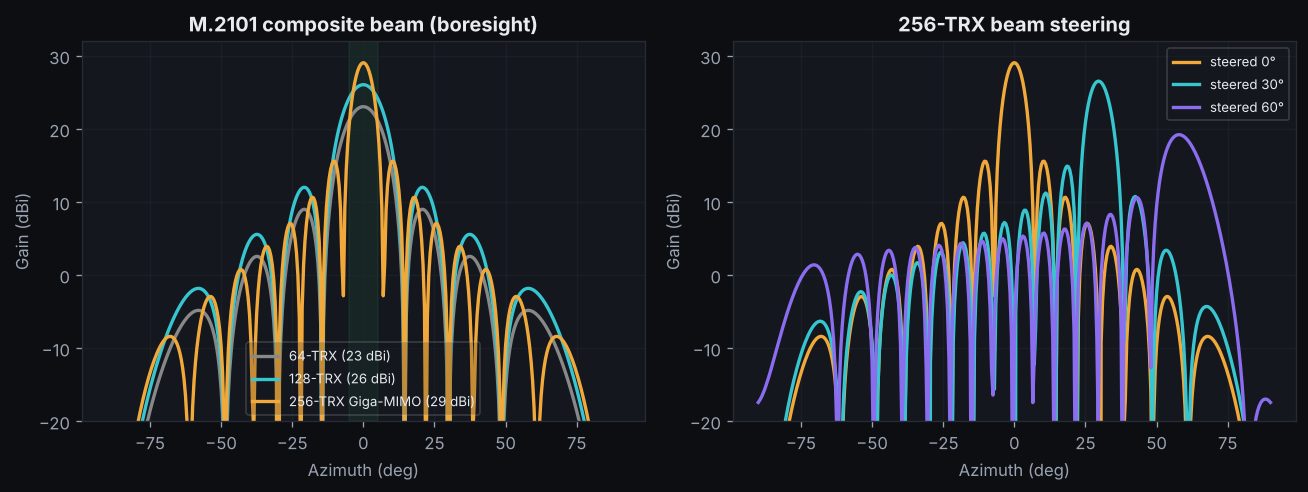

In [12]:
fig,ax=plt.subplots(1,2,figsize=(11,4.2))
azs=np.linspace(-90,90,361)
for name,lbl,col in [("macro_64","64-TRX (23 dBi)","#888"),
                     ("macro_128","128-TRX (26 dBi)",CYAN),
                     ("giga_256","256-TRX Giga-MIMO (29 dBi)",AMBER)]:
    a=IMT_ARRAYS[name]; g=[float(np.atleast_1d(a.gain(z,0,0,0))[0]) for z in azs]
    ax[0].plot(azs,g,color=col,lw=2,label=lbl)
ax[0].axvspan(-5,5,color=GREEN,alpha=0.08)
ax[0].set_title("M.2101 composite beam (boresight)")
ax[0].set_xlabel("Azimuth (deg)"); ax[0].set_ylabel("Gain (dBi)")
ax[0].set_ylim(-20,32); ax[0].grid(alpha=0.4); ax[0].legend(fontsize=8,loc="lower center")
giga=IMT_ARRAYS["giga_256"]
for steer,col in [(0,AMBER),(30,CYAN),(60,VIOLET)]:
    g=[float(np.atleast_1d(giga.gain(z,0,steer,0))[0]) for z in azs]
    ax[1].plot(azs,g,color=col,lw=2,label=f"steered {steer}°")
ax[1].set_title("256-TRX beam steering"); ax[1].set_xlabel("Azimuth (deg)"); ax[1].set_ylabel("Gain (dBi)")
ax[1].set_ylim(-20,32); ax[1].grid(alpha=0.4); ax[1].legend(fontsize=8)
plt.tight_layout()
if SAVE: plt.savefig("paper_fig1_beam_patterns.png",bbox_inches="tight")
plt.show()


### Paper Fig. 4: IMT–Wi-Fi coexistence matrix (Engine B)

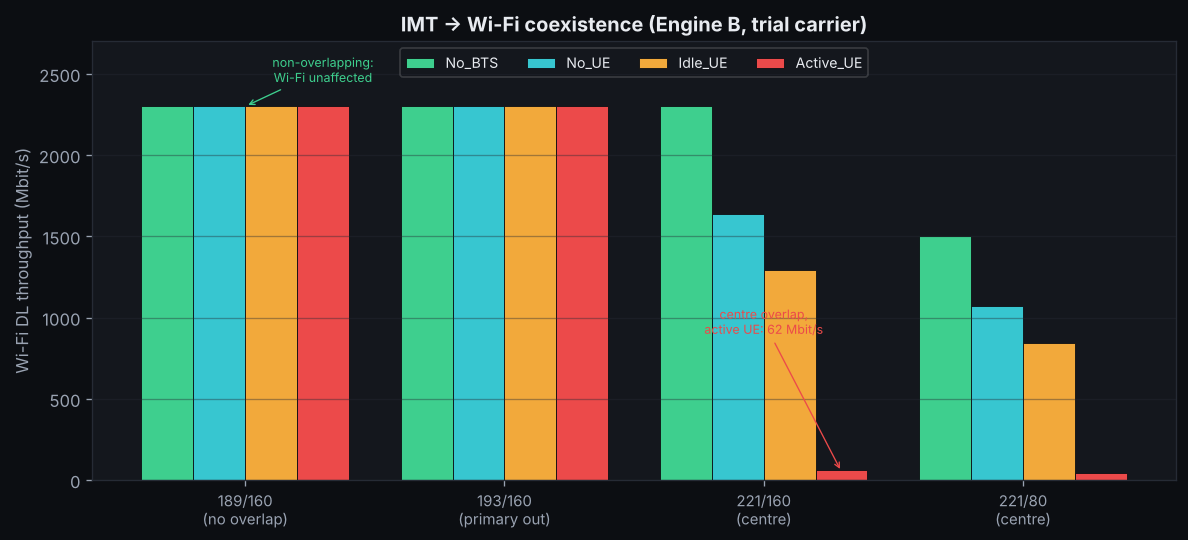

In [13]:
channels=[("189/160\n(no overlap)",6895,160),("193/160\n(primary out)",6915,160),
          ("221/160\n(centre)",7055,160),("221/80\n(centre)",7055,80)]
states=["No_BTS","No_UE","Idle_UE","Active_UE"]; scols=[GREEN,CYAN,AMBER,RED]
fig,ax=plt.subplots(figsize=(10,4.6)); x=np.arange(len(channels)); w=0.2
for i,st in enumerate(states):
    vals=[wifi_victim_throughput(st,c,b,use_ref_carrier=True) for _,c,b in channels]
    ax.bar(x+(i-1.5)*w,vals,w,label=st,color=scols[i],edgecolor="#0c0e12",lw=0.5)
ax.set_xticks(x); ax.set_xticklabels([c[0] for c in channels],fontsize=9)
ax.set_ylabel("Wi-Fi DL throughput (Mbit/s)")
ax.set_title("IMT → Wi-Fi coexistence (Engine B, trial carrier)")
ax.legend(fontsize=8.5,ncol=4,loc="upper center"); ax.grid(axis="y",alpha=0.4); ax.set_ylim(0,2700)
ax.annotate("non-overlapping:\nWi-Fi unaffected",(0,2300),(0.3,2450),fontsize=7.5,color=GREEN,ha="center",
            arrowprops=dict(arrowstyle="->",color=GREEN,lw=0.8))
ax.annotate("centre overlap,\nactive UE: 62 Mbit/s",(2.3,50),(2.0,900),fontsize=7.5,color=RED,ha="center",
            arrowprops=dict(arrowstyle="->",color=RED,lw=0.8))
plt.tight_layout()
if SAVE: plt.savefig("paper_fig4_wifi_coexistence.png",bbox_inches="tight")
plt.show()


### Wi-Fi coexistence versus operator block position
The matrix above uses the trial carrier (7050 MHz, 80 MHz), as in the calibration. The cell below moves the actual operator block across the Wi-Fi channel and shows that the Wi-Fi loss follows the spectral overlap. This is the default mode (`use_ref_carrier=False`).

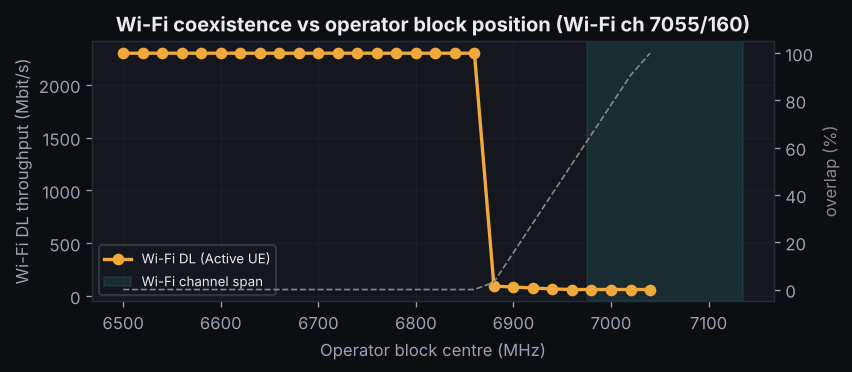

Wi-Fi is unaffected when the block does not overlap the Wi-Fi channel;
the loss follows the spectral overlap.


In [14]:
# Sweep the operator block centre across the Wi-Fi channel (7055 MHz, 160 MHz)
wifi_c, wifi_bw = 7055.0, 160.0
centres = list(range(6500, 7060, 20))
orig = CONFIG['operator_block']['center_mhz']
rows = []
for fc in centres:
    CONFIG['operator_block']['center_mhz'] = fc
    ov = overlap_fraction(fc, CONFIG['operator_block']['bandwidth_mhz'], wifi_c, wifi_bw)*100
    tp = wifi_victim_throughput('Active_UE', wifi_c, wifi_bw)  # block-tracking (default)
    rows.append((fc, ov, tp))
CONFIG['operator_block']['center_mhz'] = orig  # restore

fig, ax = plt.subplots(figsize=(7.2, 3.2))
fcs = [r[0] for r in rows]; tps = [r[2] for r in rows]; ovs = [r[1] for r in rows]
ax.plot(fcs, tps, 'o-', color=AMBER, lw=2, label='Wi-Fi DL (Active UE)')
ax.set_xlabel('Operator block centre (MHz)'); ax.set_ylabel('Wi-Fi DL throughput (Mbit/s)')
ax.set_title('Wi-Fi coexistence vs operator block position (Wi-Fi ch 7055/160)')
ax.axvspan(wifi_c-wifi_bw/2, wifi_c+wifi_bw/2, color=CYAN, alpha=0.12, label='Wi-Fi channel span')
ax.grid(alpha=0.4); ax.legend(fontsize=8)
ax2 = ax.twinx(); ax2.plot(fcs, ovs, '--', color='#888', lw=1); ax2.set_ylabel('overlap (%)', color='#888')
plt.tight_layout(); plt.show()
print('Wi-Fi is unaffected when the block does not overlap the Wi-Fi channel;')
print('the loss follows the spectral overlap.')


### Paper Fig. 3: coverage, U6 GHz versus 5G NR 3.5 GHz downlink

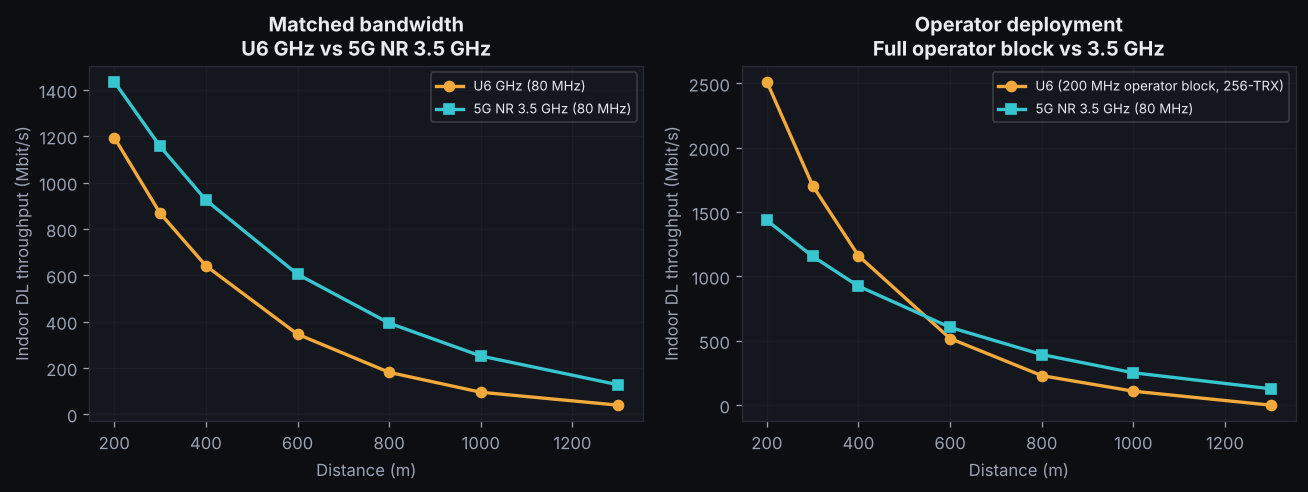

In [15]:
dists=[200,300,400,600,800,1000,1300]
cv=coverage_comparison(dists,indoor=True,validation_mode=True)
co=coverage_comparison(dists,indoor=True)
fig,ax=plt.subplots(1,2,figsize=(11,4.2))
ax[0].plot(dists,cv["u6"],"o-",color=AMBER,lw=2,label="U6 GHz (80 MHz)")
ax[0].plot(dists,cv["g35"],"s-",color=CYAN,lw=2,label="5G NR 3.5 GHz (80 MHz)")
ax[0].set_title("Matched bandwidth\nU6 GHz vs 5G NR 3.5 GHz")
ax[0].set_xlabel("Distance (m)"); ax[0].set_ylabel("Indoor DL throughput (Mbit/s)")
ax[0].legend(fontsize=8); ax[0].grid(alpha=0.4)
ax[1].plot(dists,co["u6"],"o-",color=AMBER,lw=2,label=f"U6 ({CONFIG['operator_block']['bandwidth_mhz']:.0f} MHz operator block, 256-TRX)")
ax[1].plot(dists,co["g35"],"s-",color=CYAN,lw=2,label="5G NR 3.5 GHz (80 MHz)")
ax[1].set_title("Operator deployment\nFull operator block vs 3.5 GHz")
ax[1].set_xlabel("Distance (m)"); ax[1].set_ylabel("Indoor DL throughput (Mbit/s)")
ax[1].legend(fontsize=8); ax[1].grid(alpha=0.4)
plt.tight_layout()
if SAVE: plt.savefig("paper_fig3_coverage.png",bbox_inches="tight")
plt.show()


### Paper Fig. 5: aggregate I/N into incumbents versus network size (Engine A)

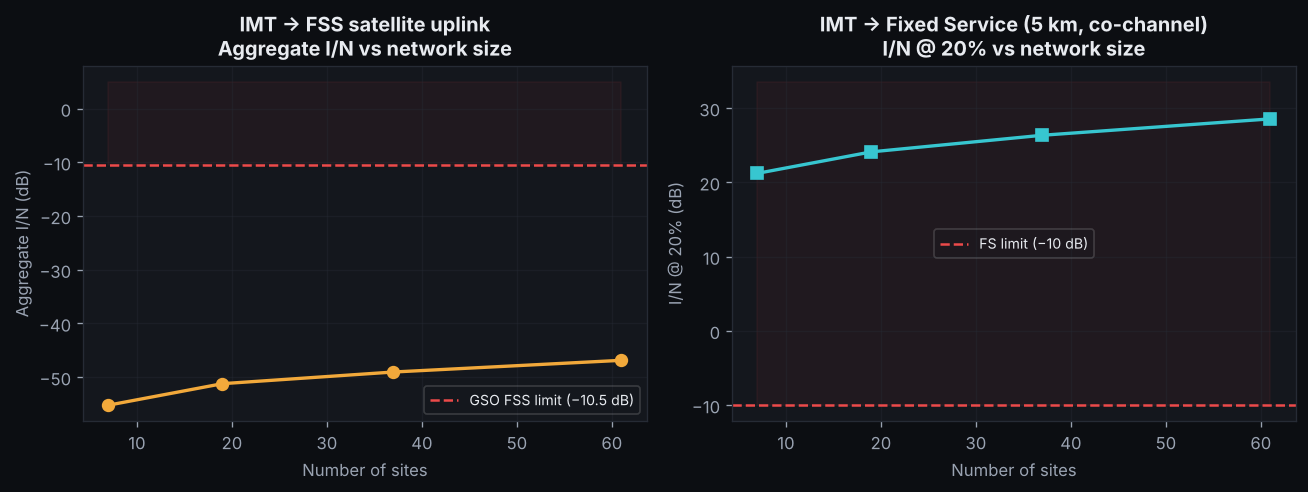

In [16]:
rings=[1,2,3,4]; sites=[n_sites(r) for r in rings]
fss_in=[mc_fss_satellite(n_rings=r,n_snap=N_SNAP_FIG)["pct"] for r in rings]
fs_in=[mc_fixed_service(n_rings=r,n_snap=N_SNAP_FIG,fs_dist_m=5000)["pct"] for r in rings]
fig,ax=plt.subplots(1,2,figsize=(11,4.2))
ax[0].plot(sites,fss_in,"o-",color=AMBER,lw=2,ms=7)
ax[0].axhline(-10.5,ls="--",color=RED,lw=1.5,label="GSO FSS limit (−10.5 dB)")
ax[0].fill_between(sites,-10.5,5,color=RED,alpha=0.06)
ax[0].set_title("IMT → FSS satellite uplink\nAggregate I/N vs network size")
ax[0].set_xlabel("Number of sites"); ax[0].set_ylabel("Aggregate I/N (dB)"); ax[0].legend(fontsize=8.5); ax[0].grid(alpha=0.4)
ax[1].plot(sites,fs_in,"s-",color=CYAN,lw=2,ms=7)
ax[1].axhline(-10,ls="--",color=RED,lw=1.5,label="FS limit (−10 dB)")
ax[1].fill_between(sites,-10,max(fs_in)+5,color=RED,alpha=0.06)
ax[1].set_title("IMT → Fixed Service (5 km, co-channel)\nI/N @ 20% vs network size")
ax[1].set_xlabel("Number of sites"); ax[1].set_ylabel("I/N @ 20% (dB)"); ax[1].legend(fontsize=8.5); ax[1].grid(alpha=0.4)
plt.tight_layout()
if SAVE: plt.savefig("paper_fig5_aggregate_scaling.png",bbox_inches="tight")
plt.show()


### Paper Fig. 7: frequency rejection and mitigation factors

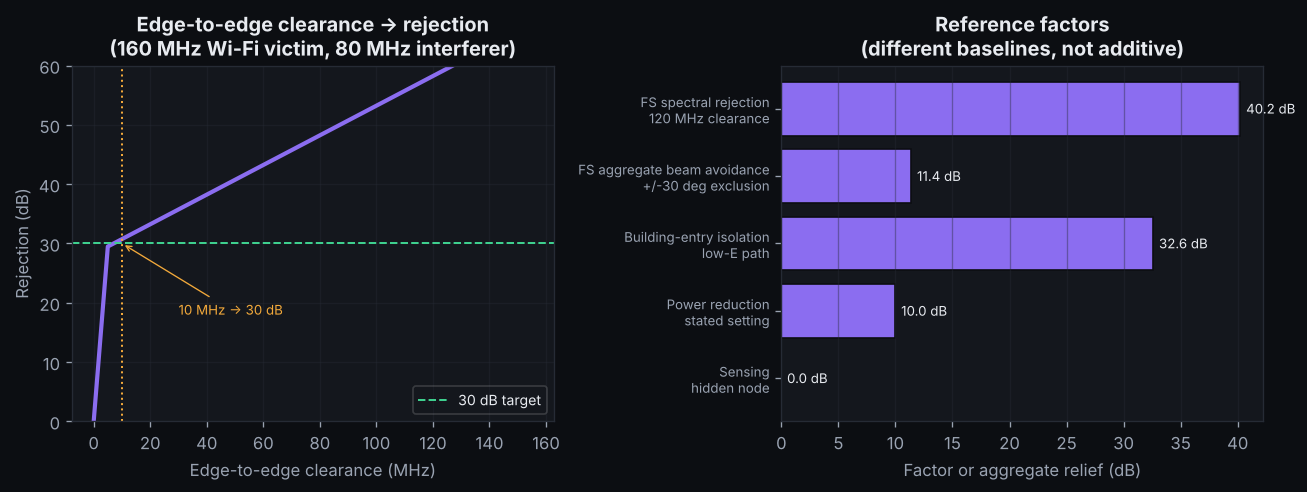

In [17]:
guards=np.arange(0,160,5)
rej=[coupling_loss_db(7055+160/2+g+80/2,80,7055,160) for g in guards]
fig,ax=plt.subplots(1,2,figsize=(11,4.2))
ax[0].plot(guards,rej,"-",color=VIOLET,lw=2.5)
ax[0].axhline(30,ls="--",color=GREEN,lw=1.2,label="30 dB target")
g30=required_guard_band(7055,160,80,30); ax[0].axvline(g30,ls=":",color=AMBER,lw=1.2)
ax[0].set_title("Edge-to-edge clearance → rejection\n(160 MHz Wi-Fi victim, 80 MHz interferer)")
ax[0].set_xlabel("Edge-to-edge clearance (MHz)"); ax[0].set_ylabel("Rejection (dB)")
ax[0].legend(fontsize=8.5); ax[0].grid(alpha=0.4); ax[0].set_ylim(0,60)
ax[0].annotate(f"{g30:.0f} MHz → 30 dB",(g30,30),(g30+20,18),fontsize=8,color=AMBER,
               arrowprops=dict(arrowstyle="->",color=AMBER,lw=0.8))
# Guard band = edge-to-edge spectral clearance between the 200 MHz block and the
# 28 MHz FS channel. Block centre for a clearance g: f_fs - B_fs/2 - g - B_blk/2.
mits=[("FS spectral rejection\n120 MHz clearance",coupling_loss_db(6739-14-120-100,200,6739,28)),
      ("FS aggregate beam avoidance\n+/-30 deg exclusion",beam_avoidance_db()),
      ("Building-entry isolation\nlow-E path",p2109_building_entry("thermally_efficient")),
      ("Power reduction\nstated setting",10.0),
      ("Sensing\nhidden node",sensing_lbt_db(-90))]
names=[m[0] for m in mits]; vals=[m[1] for m in mits]
bcols=[VIOLET]*4+["#555"]
ax[1].barh(range(len(mits)),vals,color=bcols,edgecolor="#0c0e12")
ax[1].set_yticks(range(len(mits))); ax[1].set_yticklabels(names,fontsize=8); ax[1].invert_yaxis()
ax[1].set_xlabel("Factor or aggregate relief (dB)"); ax[1].set_title("Reference factors\n(different baselines, not additive)")
ax[1].grid(axis="x",alpha=0.4)
for i,v in enumerate(vals): ax[1].text(v+0.5,i,f"{v:.1f} dB",va="center",fontsize=8,color="#e8ebf0")
plt.tight_layout()
if SAVE: plt.savefig("paper_fig7_mitigation.png",bbox_inches="tight")
plt.show()


### Paper Fig. 6: aggregate I/N distribution over the Monte Carlo snapshots

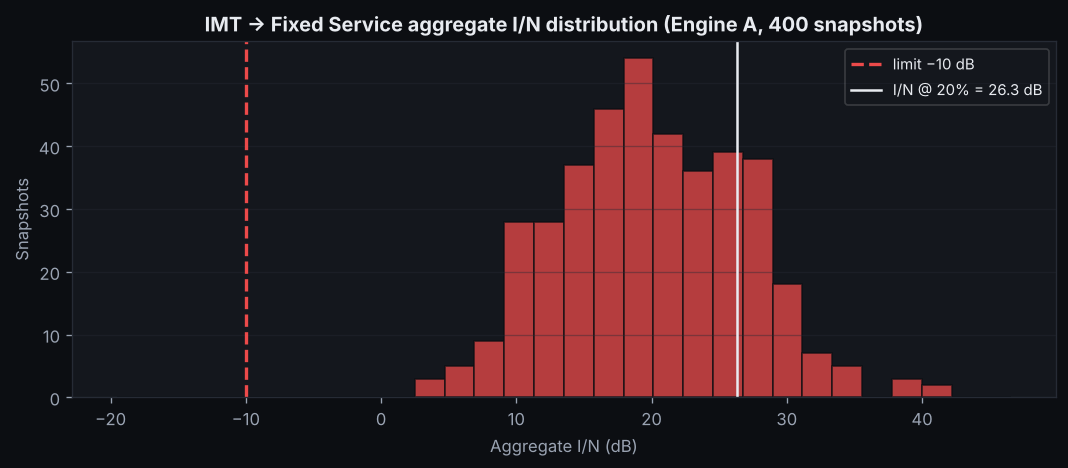

In [18]:
fsr=mc_fixed_service(n_rings=3,n_snap=N_SNAP_FIG,fs_dist_m=5000)
data=fsr["dist"]
fig,ax=plt.subplots(figsize=(9,4))
dmin,dmax=min(data.min(),-15),max(data.max(),-5); sp=dmax-dmin; dmin-=sp*0.08; dmax+=sp*0.08
n,bins,patches=ax.hist(data,bins=30,range=(dmin,dmax),edgecolor="#0c0e12")
for i,p in enumerate(patches):
    c=0.5*(bins[i]+bins[i+1]); p.set_facecolor(AMBER if c<=-10 else RED); p.set_alpha(0.75)
ax.axvline(-10,ls="--",color=RED,lw=2,label="limit −10 dB")
ax.axvline(fsr["pct"],ls="-",color="#e8ebf0",lw=1.5,label=f"I/N @ 20% = {fsr['pct']:.1f} dB")
ax.set_xlabel("Aggregate I/N (dB)"); ax.set_ylabel("Snapshots")
ax.set_title("IMT → Fixed Service aggregate I/N distribution (Engine A, 400 snapshots)")
ax.legend(fontsize=9); ax.grid(axis="y",alpha=0.4)
plt.tight_layout()
if SAVE: plt.savefig("paper_fig6_in_distribution.png",bbox_inches="tight")
plt.show()


### Paper Fig. 8: Fixed-Service I/N as mitigations are stacked
The same five steps as the paper: unmitigated, 60 MHz clearance, plus beam avoidance, 120 MHz clearance with avoidance, and a further 10 dB power reduction.

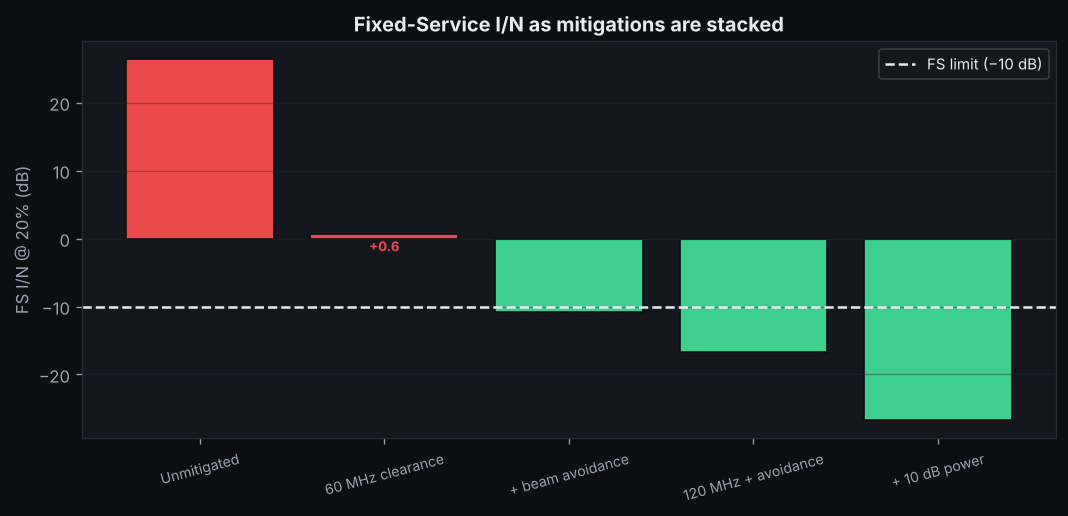

In [19]:
scenarios=[("Unmitigated",dict()),
           ("60 MHz clearance",dict(guard=60)),
           ("+ beam avoidance",dict(guard=60,beam_avoid=True)),
           ("120 MHz + avoidance",dict(guard=120,beam_avoid=True)),
           ("+ 10 dB power",dict(guard=120,beam_avoid=True,power_cut=10))]
pcts=[mc_fixed_service(n_rings=3,n_snap=N_SNAP_FIG,fs_dist_m=5000,**kw)["pct"] for _,kw in scenarios]
fig,ax=plt.subplots(figsize=(9,4.4))
cols=[RED if p>-10 else GREEN for p in pcts]
bars=ax.bar(range(len(scenarios)),pcts,color=cols,edgecolor="#0c0e12")
ax.axhline(-10,ls="--",color="#e8ebf0",lw=1.5,label="FS limit (−10 dB)")
ax.set_xticks(range(len(scenarios))); ax.set_xticklabels([s[0] for s in scenarios],fontsize=8.5,rotation=15)
ax.set_ylabel("FS I/N @ 20% (dB)"); ax.set_title("Fixed-Service I/N as mitigations are stacked")
ax.legend(fontsize=9); ax.grid(axis="y",alpha=0.4)
for i,p in enumerate(pcts):
    ax.text(i,p+(1 if p<0 else -2.5),f"{p:+.1f}",ha="center",fontsize=8,
            color=GREEN if p<=-10 else RED,fontweight="bold")
plt.tight_layout()
if SAVE: plt.savefig("paper_fig8_mitigation_stack.png",bbox_inches="tight")
plt.show()


## 12. Terminal–Wi-Fi coupling (paper Section VI.B and Fig. 9)

The preceding sections treat the downlink as the aggressor (75 dBm base-station EIRP). On an uplink-only or supplemental-uplink (SUL) carrier the aggressor is the device: a 26 dBm handheld or a 31 dBm rooftop CPE, both as EIRP. Both directions of local coupling are evaluated at a device–AP separation, each against the criterion used in the paper:

1. device to Wi-Fi AP: received interference below the −72 dBm transition level of the airtime model (`P_ED`), so that no airtime loss is assigned;
2. Wi-Fi AP to device receiver: I/N below the −6 dB IMT criterion (`PROTECTION['IMT']`).

Frequency coordination is represented by the AFC assignment, which moves the mobile carrier clear of the Wi-Fi channel (a 180 MHz centre separation for 160 MHz channels). These are terminal-level budgets: they do not model the serving base-station receive location and do not establish protection of the base-station uplink receiver.

In [20]:
UL_DEVICES = {
    'handheld':    dict(eirp=26.0, gain=17.04, regime='o2i'),  # handheld, 26 dBm EIRP
    'cpe_rooftop': dict(eirp=31.0, gain=23.0,  regime='o2i'),  # rooftop CPE, 31 dBm EIRP (array)
}
WIFI_AP = dict(tx=23.0, gain=6.0)  # indoor Wi-Fi AP

def ul_coexistence(device, wifi_c, wifi_bw, dist_m, afc, cfg=CONFIG):
    """Uplink IMT<->Wi-Fi coexistence at a device-AP separation dist_m (metres).
    Worst-case co-channel scenario; AFC (if on) assigns a clear channel.
    Returns per-direction levels and whether each meets its criterion (paper Section VI.B)."""
    dev = UL_DEVICES[device]
    wifi_base = 2300.0 if wifi_bw>=160 else 1500.0
    mC, mBw = wifi_c, min(cfg['operator_block']['bandwidth_mhz'], wifi_bw)  # co-channel
    # AFC: move the IMT carrier clear of the Wi-Fi channel with a 20 MHz guard
    afc_shift = 0.0
    if afc:
        need = (mBw+wifi_bw)/2 + 20.0
        # try shifting up first, else down, to stay inside the band
        for target in (wifi_c + need, wifi_c - need):
            if 6425+mBw/2 <= target <= 7125-mBw/2:
                mC, afc_shift = target, need
                break
    rej = coupling_loss_db(mC, mBw, wifi_c, wifi_bw)
    ov  = overlap_fraction(mC, mBw, wifi_c, wifi_bw)
    # AFC standard-power EIRP cap if still co-channel
    dev_eirp = min(dev['eirp'], 21.0) if (afc and ov>0) else dev['eirp']
    # Direction 1: IMT UL device -> Wi-Fi AP
    pl1 = total_path_loss(mC, max(dist_m,1), dev['regime'], cfg['deployment']['building'])
    rx_ap = dev_eirp + WIFI_AP['gain'] - pl1 - rej
    n_wifi = -174 + 10*np.log10(wifi_bw*1e6) + 7
    in_ap = rx_ap - n_wifi
    wifi_tp = wifi_base*(1-airtime_loss(rx_ap, ov))
    # Direction 2: Wi-Fi AP -> IMT UL device receiver
    pl2 = total_path_loss(mC, max(dist_m,1), dev['regime'], cfg['deployment']['building'])
    rx_dev = WIFI_AP['tx'] + dev['gain'] - pl2 - rej
    n_dev = -174 + 10*np.log10(mBw*1e6) + 9
    in_dev = rx_dev - n_dev
    wifi_ok = rx_ap < P_ED                               # below the -72 dBm transition: no airtime loss
    imt_ok  = in_dev < PROTECTION['IMT'].threshold_db    # IMT criterion, I/N < -6 dB
    return dict(device=device, dist=dist_m, afc_shift=afc_shift, overlap=ov,
                rx_ap=rx_ap, in_ap=in_ap, wifi_loss=(1-wifi_tp/wifi_base)*100, wifi_ok=wifi_ok,
                in_dev=in_dev, imt_ok=imt_ok, both_met=(wifi_ok and imt_ok))

# Demonstrate at 20 m: co-channel vs coordinated, for both device classes
print('TERMINAL–Wi-Fi COUPLING (Wi-Fi ch 7055/160, device–AP separation 20 m)')
print('='*74)
met={}
for dev in ['handheld','cpe_rooftop']:
    for afc in [False, True]:
        r = ul_coexistence(dev, 7055, 160, 20, afc); met[(dev,afc)] = r['both_met']
        tag = 'coordinated' if afc else 'co-channel '
        verdict = 'both criteria met' if r['both_met'] else 'criterion exceeded'
        print(f"  {dev:12s} {tag}: device->AP {r['rx_ap']:6.1f} dBm   AP->device I/N {r['in_dev']:+6.1f} dB  -> {verdict}")
print()
print(f"At 20 m, co-channel operation meets both criteria for {sum(met[(d,False)] for d in ['handheld','cpe_rooftop'])} of 2 device classes;")
print(f"with frequency coordination, for {sum(met[(d,True)] for d in ['handheld','cpe_rooftop'])} of 2. Closer separations are examined below.")
print('These are terminal-level budgets, not protection of the base-station uplink receiver.')


TERMINAL–Wi-Fi COUPLING (Wi-Fi ch 7055/160, device–AP separation 20 m)
  handheld     co-channel : device->AP  -82.0 dBm   AP->device I/N   +9.0 dB  -> criterion exceeded
  handheld     coordinated: device->AP -112.5 dBm   AP->device I/N  -21.5 dB  -> both criteria met
  cpe_rooftop  co-channel : device->AP  -77.0 dBm   AP->device I/N  +15.0 dB  -> criterion exceeded
  cpe_rooftop  coordinated: device->AP -107.5 dBm   AP->device I/N  -15.5 dB  -> both criteria met

At 20 m, co-channel operation meets both criteria for 0 of 2 device classes;
with frequency coordination, for 2 of 2. Closer separations are examined below.
These are terminal-level budgets, not protection of the base-station uplink receiver.


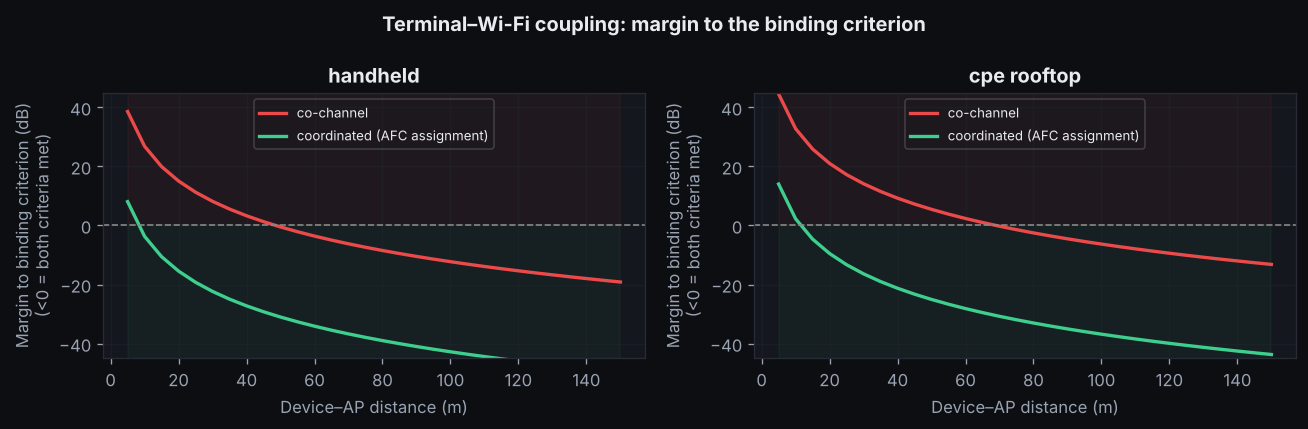

handheld     coordinated: margin at 5 m +8.1 dB (AP->device binding); both criteria met from 10 m
cpe_rooftop  coordinated: margin at 5 m +14.0 dB (AP->device binding); both criteria met from 15 m

Paper Section VI.B values (coordinated): device->AP at 5 m, and AP->device I/N at 5/10/20 m
  handheld     -88.94 dBm;  +2.06 / -9.70 / -21.47 dB
  cpe_rooftop  -83.94 dBm;  +8.02 / -3.74 / -15.51 dB


In [21]:
# Figure: margin to the binding criterion versus separation, co-channel vs coordinated.
# Margin > 0 means a criterion is exceeded: device->AP is measured against the -72 dBm
# transition (P_ED); AP->device against the -6 dB IMT criterion (exceedance = I/N + 6 dB).
dists = list(range(5, 155, 5))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6)); summary = {}
for ax, dev in zip(axes, ['handheld','cpe_rooftop']):
    for afc, col, lbl in [(False, RED, 'co-channel'), (True, GREEN, 'coordinated (AFC assignment)')]:
        worst, bind = [], []
        for d in dists:
            r = ul_coexistence(dev, 7055, 160, d, afc)
            m_wifi = r['rx_ap'] - P_ED
            m_imt  = r['in_dev'] - PROTECTION['IMT'].threshold_db
            worst.append(max(m_wifi, m_imt)); bind.append('AP->device' if m_imt >= m_wifi else 'device->AP')
        summary[(dev, afc)] = (worst, bind)
        ax.plot(dists, worst, '-', color=col, lw=2, label=lbl)
    ax.axhline(0, ls='--', color='#888', lw=1)
    ax.fill_between(dists, 0, 60, color=RED, alpha=0.05)
    ax.fill_between(dists, -60, 0, color=GREEN, alpha=0.05)
    ax.set_title(f"{dev.replace('_',' ')}"); ax.set_xlabel('Device–AP distance (m)')
    ax.set_ylabel('Margin to binding criterion (dB)\n(<0 = both criteria met)'); ax.set_ylim(-45, 45)
    ax.grid(alpha=0.35); ax.legend(fontsize=8)
plt.suptitle('Terminal–Wi-Fi coupling: margin to the binding criterion', fontweight='bold')
plt.tight_layout(); plt.savefig('paper_fig9_terminal_coupling.png', dpi=150, bbox_inches='tight'); plt.show()
for dev in ['handheld','cpe_rooftop']:
    w, b = summary[(dev, True)]
    first = next((d for j, d in enumerate(dists) if all(x < 0 for x in w[j:])), None)
    print(f"{dev:12s} coordinated: margin at 5 m {w[0]:+.1f} dB ({b[0]} binding); "
          + (f"both criteria met from {first} m" if first else "criteria not met within 150 m"))
print('\nPaper Section VI.B values (coordinated): device->AP at 5 m, and AP->device I/N at 5/10/20 m')
for dev in ['handheld','cpe_rooftop']:
    v = [ul_coexistence(dev, 7055, 160, d, True) for d in (5, 10, 20)]
    print(f"  {dev:12s} {v[0]['rx_ap']:.2f} dBm;  " + ' / '.join(f"{x['in_dev']:+.2f}" for x in v) + ' dB')


## 13. Sensitivity analysis (paper Fig. 10)

Sweeps inter-site distance, array size, channel bandwidth and cell traffic load. Every Fixed-Service value is the 80th percentile (`pct`), the statistic used for the reference result in Section V.B of the paper, so the baseline point of each sweep equals that result.

Baseline (37 sites, 50% load, 256-TRX): FS I/N@20% = +26.3 dB


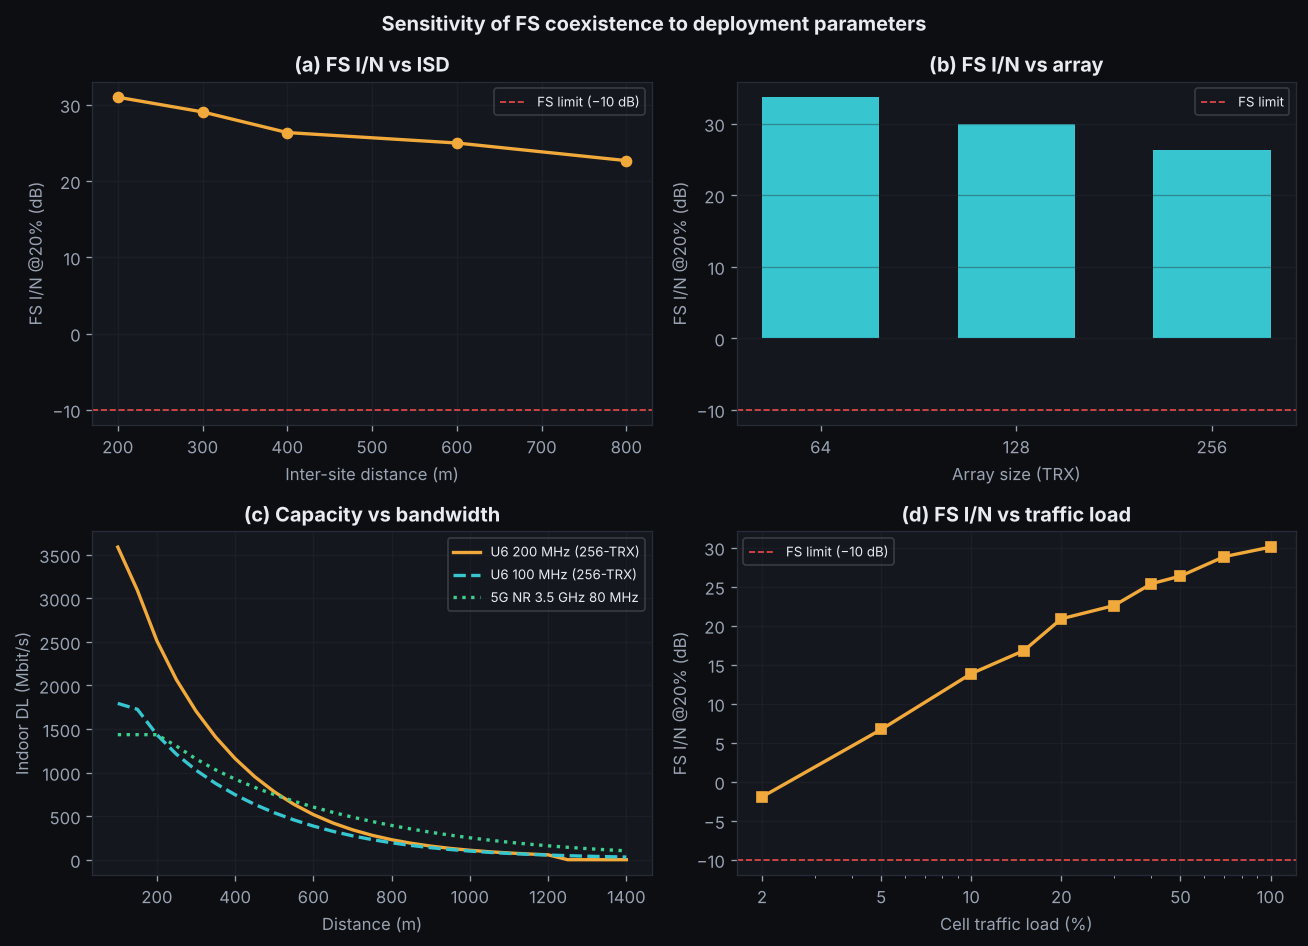

ISD   [(200, 31.0), (300, 29.1), (400, 26.3), (600, 25.0), (800, 22.7)]
Array [('64', 33.7), ('128', 30.0), ('256', 26.3)]


In [22]:
import copy
NSNAP_SENS = 400   # same snapshot count as the headline evaluation

def _cfg(**kw):
    c = copy.deepcopy(CONFIG)
    if 'isd'   in kw: c['deployment']['isd_m']   = kw['isd']
    if 'load'  in kw: c['deployment']['cell_load'] = kw['load']
    if 'array' in kw: c['imt_bs']['array']       = kw['array']
    if 'bw'    in kw: c['operator_block']['bandwidth_mhz'] = kw['bw']
    return c

def fs_pct(cfg, rings=3):
    """20% protection percentile of the aggregate FS I/N."""
    return mc_fixed_service(cfg=cfg, n_rings=rings, n_snap=NSNAP_SENS,
                            rng=np.random.default_rng(42))['pct']

base = fs_pct(CONFIG)
print(f'Baseline (37 sites, 50% load, 256-TRX): FS I/N@20% = {base:+.1f} dB')

isds  = [200, 300, 400, 600, 800]
arrays= [('macro_64','64'), ('macro_128','128'), ('giga_256','256')]
loads = [0.02, 0.05, 0.10, 0.15, 0.20, 0.30, 0.40, 0.50, 0.70, 1.0]
v_isd  = [fs_pct(_cfg(isd=x))   for x in isds]
v_arr  = [fs_pct(_cfg(array=a)) for a,_ in arrays]
v_load = [fs_pct(_cfg(load=l))  for l in loads]

fig, ax = plt.subplots(2, 2, figsize=(11, 8))
ax[0,0].plot(isds, v_isd, 'o-', color=AMBER, lw=2)
ax[0,0].axhline(-10, ls='--', color=RED, lw=1, label='FS limit (−10 dB)')
ax[0,0].set_xlabel('Inter-site distance (m)'); ax[0,0].set_ylabel('FS I/N @20% (dB)')
ax[0,0].set_title('(a) FS I/N vs ISD'); ax[0,0].grid(alpha=.4); ax[0,0].legend(fontsize=8)

ax[0,1].bar([n for _,n in arrays], v_arr, color=CYAN, width=.6)
ax[0,1].axhline(-10, ls='--', color=RED, lw=1, label='FS limit')
ax[0,1].set_xlabel('Array size (TRX)'); ax[0,1].set_ylabel('FS I/N @20% (dB)')
ax[0,1].set_title('(b) FS I/N vs array'); ax[0,1].grid(axis='y', alpha=.4); ax[0,1].legend(fontsize=8)

dd = list(range(100, 1401, 50))
for bw, col, ls in [(200, AMBER, '-'), (100, CYAN, '--')]:
    rc = coverage_comparison(dd, cfg=_cfg(bw=bw))
    ax[1,0].plot(dd, rc['u6'], ls, color=col, lw=2, label=f'U6 {bw} MHz (256-TRX)')
rc0 = coverage_comparison(dd, cfg=CONFIG)
ax[1,0].plot(dd, rc0['g35'], ':', color=GREEN, lw=2, label='5G NR 3.5 GHz 80 MHz')
ax[1,0].set_xlabel('Distance (m)'); ax[1,0].set_ylabel('Indoor DL (Mbit/s)')
ax[1,0].set_title('(c) Capacity vs bandwidth'); ax[1,0].grid(alpha=.4); ax[1,0].legend(fontsize=8)

ax[1,1].plot([l*100 for l in loads], v_load, 's-', color=AMBER, lw=2)
ax[1,1].axhline(-10, ls='--', color=RED, lw=1, label='FS limit (−10 dB)')
ax[1,1].set_xscale('log'); ax[1,1].set_xticks([2,5,10,20,50,100])
ax[1,1].set_xticklabels(['2','5','10','20','50','100'])
ax[1,1].set_xlabel('Cell traffic load (%)'); ax[1,1].set_ylabel('FS I/N @20% (dB)')
ax[1,1].set_title('(d) FS I/N vs traffic load'); ax[1,1].grid(alpha=.4); ax[1,1].legend(fontsize=8)

plt.suptitle('Sensitivity of FS coexistence to deployment parameters', fontweight='bold')
plt.tight_layout(); plt.savefig('paper_fig10_sensitivity.png', dpi=150, bbox_inches='tight'); plt.show()

cross = None
for i in range(len(loads)-1):
    if (v_load[i]+10) * (v_load[i+1]+10) < 0:
        f = (-10 - v_load[i]) / (v_load[i+1] - v_load[i])
        cross = loads[i] + f*(loads[i+1]-loads[i]); break
print(f'ISD   {list(zip(isds, [round(x,1) for x in v_isd]))}')
print(f'Array {list(zip([n for _,n in arrays], [round(x,1) for x in v_arr]))}')
if cross: print(f'Load crosses the -10 dB criterion near {cross*100:.0f}% loading')


### Paper Fig. 11(a) and (b): victim distance and dish pointing

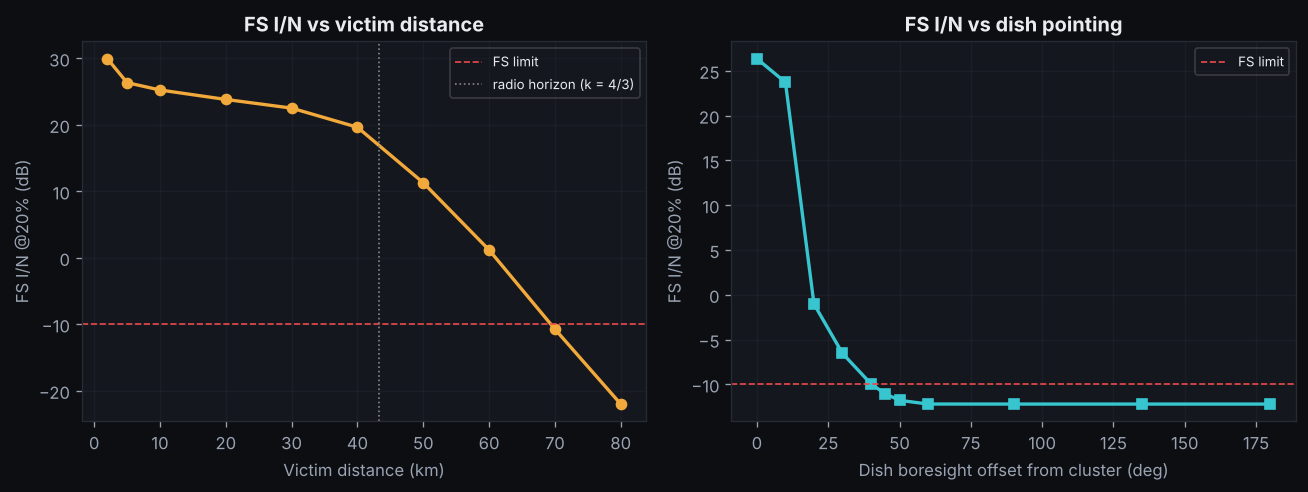

distance (km, dB): [(2, 30.0), (5, 26.3), (10, 25.2), (20, 23.8), (30, 22.5), (40, 19.6), (50, 11.3), (60, 1.2), (70, -10.7), (80, -22.0)]
pointing (deg, dB): [(0, 26.3), (10, 23.7), (20, -1.0), (30, -6.5), (40, -9.9), (45, -11.1), (50, -11.8), (60, -12.2), (90, -12.2), (135, -12.2), (180, -12.2)]


In [23]:
# Paper Fig. 11(a)-(b): victim distance (P.452, radio horizon) and dish pointing
dists_km=[2,5,10,20,30,40,50,60,70,80]
offs=[0,10,20,30,40,45,50,60,90,135,180]
v_d=[mc_fixed_service(fs_dist_m=d*1000,rng=np.random.default_rng(42))["pct"] for d in dists_km]
v_o=[mc_fixed_service(fs_boresight_offset=o,rng=np.random.default_rng(42))["pct"] for o in offs]
fig,ax=plt.subplots(1,2,figsize=(11,4.2))
ax[0].plot(dists_km,v_d,"o-",color=AMBER,lw=2); ax[0].axhline(-10,ls="--",color=RED,lw=1,label="FS limit")
ax[0].axvline(43.2,ls=":",color="#888",lw=1,label="radio horizon (k = 4/3)")
ax[0].set_xlabel("Victim distance (km)"); ax[0].set_ylabel("FS I/N @20% (dB)"); ax[0].set_title("FS I/N vs victim distance")
ax[0].grid(alpha=.4); ax[0].legend(fontsize=8)
ax[1].plot(offs,v_o,"s-",color=CYAN,lw=2); ax[1].axhline(-10,ls="--",color=RED,lw=1,label="FS limit")
ax[1].set_xlabel("Dish boresight offset from cluster (deg)"); ax[1].set_ylabel("FS I/N @20% (dB)"); ax[1].set_title("FS I/N vs dish pointing")
ax[1].grid(alpha=.4); ax[1].legend(fontsize=8)
plt.tight_layout()
if SAVE: plt.savefig("paper_fig11ab_distance_pointing.png",bbox_inches="tight")
plt.show()
print("distance (km, dB):", [(d,round(v,1)) for d,v in zip(dists_km,v_d)])
print("pointing (deg, dB):", [(o,round(v,1)) for o,v in zip(offs,v_o)])


## 14. Summary
Text summary of the results for the current `CONFIG`.

In [24]:
print("="*64)
print(f"  U6 GHz interference study: {CONFIG['meta']['name']}")
print(f"  Band {CONFIG['band']['f_start']:.0f}-{CONFIG['band']['f_stop']:.0f} MHz ({CONFIG['meta']['band_3gpp']})")
ob=CONFIG['operator_block']
print(f"  operator block {ob['center_mhz']-ob['bandwidth_mhz']/2:.0f}-{ob['center_mhz']+ob['bandwidth_mhz']/2:.0f} MHz ({ob['bandwidth_mhz']:.0f} MHz)")
print("="*64)
fs=mc_fixed_service(n_rings=3,n_snap=N_SNAP_FIG); fss=mc_fss_satellite(n_rings=3,n_snap=N_SNAP_FIG)
print(f"\nEngine A: aggregate interference into incumbents")
print(f"  FSS satellite : I/N(80th pctile) {fss['pct']:+.1f} dB  [{'PASS' if fss['passes'] else 'FAIL'}]  margin {fss['margin']:+.1f} dB")
print(f"  Fixed Service : I/N {fs['pct']:+.1f} dB @20%  [{'PASS' if fs['passes'] else 'FAIL'}]  margin {fs['margin']:+.1f} dB")
print(f"\nEngine B: IMT–Wi-Fi (active UE, centre-overlapping ch221/160, trial carrier)")
wv=wifi_victim_throughput("Active_UE",7055,160,use_ref_carrier=True); loss=(1-wv/2300)*100
print(f"  Wi-Fi DL loss: {loss:.0f}% ({wv:.0f} of 2300 Mbit/s)")
print(f"\nMitigation (Fixed Service, co-channel)")
need=max(0,-fs['margin'])
print(f"  reduction needed : {need:.1f} dB")
print(f"  guard band 30 dB : {required_guard_band(7055,160,80,30):.0f} MHz (Wi-Fi victim)")
print(f"  beam avoidance   : {beam_avoidance_db():.1f} dB (aggregate, +/-30 deg exclusion)")
print("  AFC (registered) : acts through the assigned clearance")
print("\n" + "="*64)
print("Figures saved as *.png in the working directory.")
print("Edit CONFIG (Section 5) and re-run all to update everything.")


  U6 GHz interference study: U6GHz coexistence study (n104)
  Band 6425-7125 MHz (n104)
  operator block 6525-6725 MHz (200 MHz)



Engine A: aggregate interference into incumbents
  FSS satellite : I/N(80th pctile) -49.0 dB  [PASS]  margin +38.5 dB
  Fixed Service : I/N +26.3 dB @20%  [FAIL]  margin -36.3 dB

Engine B: IMT–Wi-Fi (active UE, centre-overlapping ch221/160, trial carrier)
  Wi-Fi DL loss: 97% (62 of 2300 Mbit/s)

Mitigation (Fixed Service, co-channel)
  reduction needed : 36.3 dB
  guard band 30 dB : 10 MHz (Wi-Fi victim)


  beam avoidance   : 11.4 dB (aggregate, +/-30 deg exclusion)
  AFC (registered) : acts through the assigned clearance

Figures saved as *.png in the working directory.
Edit CONFIG (Section 5) and re-run all to update everything.
